# Rogue AP Detection System - Detection Rules Implementation

This notebook demonstrates the implementation of six detection rules for identifying rogue access points in IEEE 802.11 wireless networks.

## Dataset

- **Source**: Belgian Train Station Wireless Capture
- **Capture 1**: 36,306 frames
- **Capture 2**: 60,984 frames
- **Total**: 97,290 wireless frames

## Detection Rules

| # | Rule | Severity | Description |
|---|------|----------|-------------|
| 1 | SSID Spoofing | HIGH | Detects evil twin attacks |
| 2 | MAC Address Inconsistency | HIGH | Frame injection detection |
| 3 | RSSI Anomaly | MEDIUM | Statistical outlier detection |
| 4 | Probe Response Flood | LOW | Honeypot detection |
| 5 | MAC Timestamp Drift | LOW | Replay attack detection |
| 6 | Unknown BSSID | MEDIUM | Unauthorized AP detection |

---

# 1. Setup and Data Loading

Import required libraries and load the wireless capture datasets.

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# Color schemes
COLORS = {
    'primary': '#4EC9B0',
    'secondary': '#CE9178',
    'danger': '#F44747',
    'safe': '#4EC9B0',
    'warning': '#DCDCAA',
    'info': '#569CD6'
}

# Define paths
CAPTURE_1 = '../datasets/1/capture-1.csv'
CAPTURE_2 = '../datasets/2/capture-2.csv'

In [3]:
# Load datasets
df1 = pd.read_csv(CAPTURE_1)
df2 = pd.read_csv(CAPTURE_2)

# Combine datasets for analysis
df = pd.concat([df1, df2], ignore_index=True)

print(f"Dataset 1: {len(df1):,} frames")
print(f"Dataset 2: {len(df2):,} frames")
print(f"Combined: {len(df):,} frames")

# Clean SSID column (remove b'' wrapper)
df['SSID'] = df['SSID'].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False)
df1['SSID'] = df1['SSID'].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False)
df2['SSID'] = df2['SSID'].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False)

# Add capture label
df1['capture'] = 'Capture 1'
df2['capture'] = 'Capture 2'

df.head()

Dataset 1: 36,306 frames
Dataset 2: 60,984 frames
Combined: 97,290 frames


,Timestamp,type,MAC_timestamp,rssi,addr1,addr2,addr3,SSID
0,1.682624e+09,Dot11ProbeReq,698923371,-61,ff:ff:ff:ff:ff:ff,00:00:00:00:00:02,ff:ff:ff:ff:ff:ff,
1,1.682624e+09,Dot11Beacon,698926457,-49,ff:ff:ff:ff:ff:ff,00:00:00:00:00:03,00:00:00:00:00:03,NETWORK_1
2,1.682624e+09,Dot11ProbeResp,698927083,-49,00:00:00:00:00:02,00:00:00:00:00:04,00:00:00:00:00:04,NETWORK_2
3,1.682624e+09,Dot11ProbeResp,698927392,-49,00:00:00:00:00:02,00:00:00:00:00:05,00:00:00:00:00:05,NETWORK_3
4,1.682624e+09,Dot11ProbeResp,698928136,-49,00:00:00:00:00:02,00:00:00:00:00:05,00:00:00:00:00:05,NETWORK_3


---

# 2. Data Overview

## 2.1 Dataset Structure and Statistics

In [4]:
# Dataset structure
print("=" * 60)
print("DATASET STRUCTURE")
print("=" * 60)
print("\nColumns:")
print(df.columns.tolist())
print("\nData Types:")
print(df.dtypes)
print("\n--- Frame Types Distribution ---")
print(df['type'].value_counts())

DATASET STRUCTURE

Columns:
['Timestamp', 'type', 'MAC_timestamp', 'rssi', 'addr1', 'addr2', 'addr3', 'SSID']

Data Types:
Timestamp        float64
type                 str
MAC_timestamp      int64
rssi               int64
addr1                str
addr2                str
addr3                str
SSID                 str
dtype: object

--- Frame Types Distribution ---
type
Dot11Beacon       47676
Dot11ProbeResp    47236
Dot11ProbeReq      2378
Name: count, dtype: int64


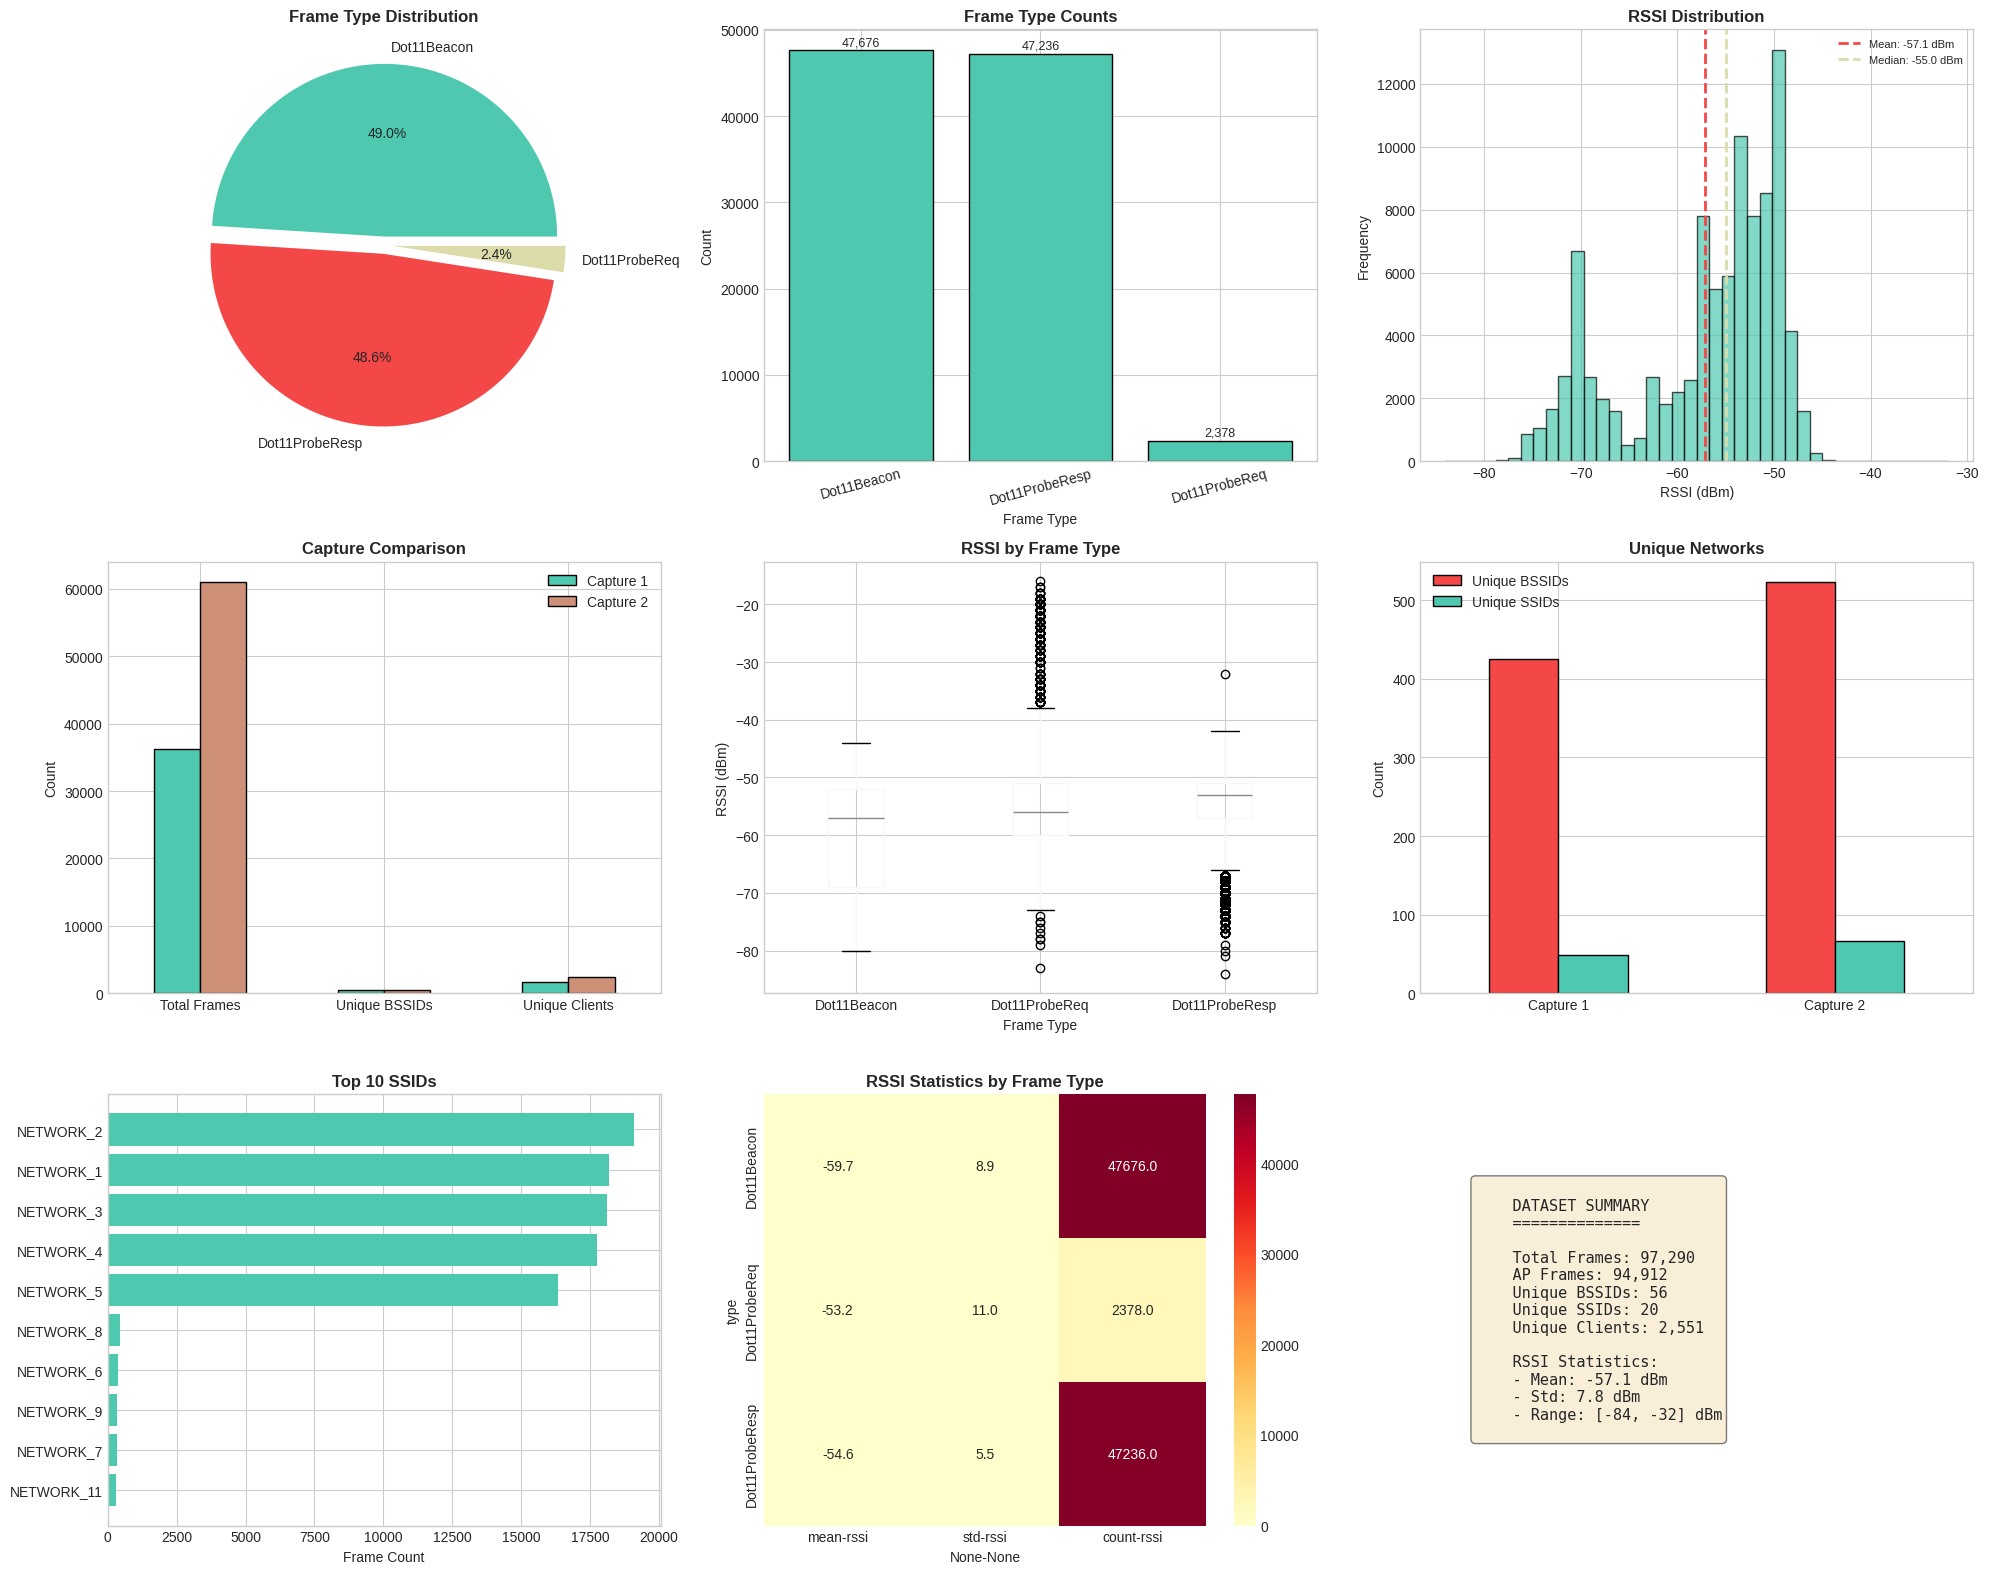

In [5]:
# Comprehensive Visualization Dashboard
fig = plt.figure(figsize=(20, 16))

# 1. Frame Type Distribution - Pie Chart
ax1 = fig.add_subplot(3, 3, 1)
frame_counts = df['type'].value_counts()
colors = [COLORS['primary'], COLORS['danger'], COLORS['warning'], COLORS['secondary']]
wedges, texts, autotexts = ax1.pie(frame_counts.values, labels=frame_counts.index, 
                                   autopct='%1.1f%%', colors=colors[:len(frame_counts)],
                                   explode=[0.05]*len(frame_counts))
ax1.set_title('Frame Type Distribution', fontsize=12, fontweight='bold')

# 2. Frame Type Count - Bar Chart
ax2 = fig.add_subplot(3, 3, 2)
bars = ax2.bar(frame_counts.index, frame_counts.values, color=COLORS['primary'], edgecolor='black')
ax2.set_xlabel('Frame Type')
ax2.set_ylabel('Count')
ax2.set_title('Frame Type Counts', fontsize=12, fontweight='bold')
for bar, count in zip(bars, frame_counts.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, 
             f'{count:,}', ha='center', va='bottom', fontsize=9)
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=15)

# 3. RSSI Distribution - Histogram
ax3 = fig.add_subplot(3, 3, 3)
ap_frames = df[df['type'].isin(['Dot11Beacon', 'Dot11ProbeResp'])]
ax3.hist(ap_frames['rssi'], bins=40, color=COLORS['primary'], edgecolor='black', alpha=0.7)
ax3.axvline(ap_frames['rssi'].mean(), color=COLORS['danger'], linestyle='--', linewidth=2, 
            label=f'Mean: {ap_frames["rssi"].mean():.1f} dBm')
ax3.axvline(ap_frames['rssi'].median(), color=COLORS['warning'], linestyle='--', linewidth=2, 
            label=f'Median: {ap_frames["rssi"].median():.1f} dBm')
ax3.set_xlabel('RSSI (dBm)')
ax3.set_ylabel('Frequency')
ax3.set_title('RSSI Distribution', fontsize=12, fontweight='bold')
ax3.legend(fontsize=8)

# 4. Capture Comparison - Side by Side
ax4 = fig.add_subplot(3, 3, 4)
capture_stats = pd.DataFrame({
    'Capture 1': [len(df1), df1['addr2'].nunique(), df1['addr1'].nunique()],
    'Capture 2': [len(df2), df2['addr2'].nunique(), df2['addr1'].nunique()]
}, index=['Total Frames', 'Unique BSSIDs', 'Unique Clients'])
capture_stats.plot(kind='bar', ax=ax4, color=[COLORS['primary'], COLORS['secondary']], edgecolor='black')
ax4.set_title('Capture Comparison', fontsize=12, fontweight='bold')
ax4.set_ylabel('Count')
ax4.tick_params(axis='x', rotation=0)

# 5. RSSI Box Plot by Frame Type
ax5 = fig.add_subplot(3, 3, 5)
df.boxplot(column='rssi', by='type', ax=ax5)
ax5.set_xlabel('Frame Type')
ax5.set_ylabel('RSSI (dBm)')
ax5.set_title('RSSI by Frame Type', fontsize=12, fontweight='bold')
plt.suptitle('')

# 6. Unique Networks per Capture
ax6 = fig.add_subplot(3, 3, 6)
networks = pd.DataFrame({
    'Capture 1': [df1['addr2'].nunique(), df1[df1['SSID'] != '']['SSID'].nunique()],
    'Capture 2': [df2['addr2'].nunique(), df2[df2['SSID'] != '']['SSID'].nunique()]
}, index=['Unique BSSIDs', 'Unique SSIDs'])
networks.T.plot(kind='bar', ax=ax6, color=[COLORS['danger'], COLORS['primary']], edgecolor='black')
ax6.set_title('Unique Networks', fontsize=12, fontweight='bold')
ax6.set_ylabel('Count')
ax6.tick_params(axis='x', rotation=0)

# 7. Top 10 SSIDs by Frame Count
ax7 = fig.add_subplot(3, 3, 7)
ssid_counts = ap_frames[ap_frames['SSID'] != '']['SSID'].value_counts().head(10)
ax7.barh(range(len(ssid_counts)), ssid_counts.values, color=COLORS['primary'])
ax7.set_yticks(range(len(ssid_counts)))
ax7.set_yticklabels([s[:15] + '...' if len(s) > 15 else s for s in ssid_counts.index])
ax7.set_xlabel('Frame Count')
ax7.set_title('Top 10 SSIDs', fontsize=12, fontweight='bold')
ax7.invert_yaxis()

# 8. RSSI Heatmap by Frame Type
ax8 = fig.add_subplot(3, 3, 8)
heatmap_data = df.pivot_table(values='rssi', index='type', aggfunc=['mean', 'std', 'count'])
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax8)
ax8.set_title('RSSI Statistics by Frame Type', fontsize=12, fontweight='bold')

# 9. Network Statistics Summary
ax9 = fig.add_subplot(3, 3, 9)
ax9.axis('off')
summary_text = f"""
    DATASET SUMMARY
    ==============
    
    Total Frames: {len(df):,}
    AP Frames: {len(ap_frames):,}
    Unique BSSIDs: {ap_frames['addr2'].nunique():,}
    Unique SSIDs: {ap_frames[ap_frames['SSID'] != '']['SSID'].nunique():,}
    Unique Clients: {ap_frames['addr1'].nunique():,}
    
    RSSI Statistics:
    - Mean: {ap_frames['rssi'].mean():.1f} dBm
    - Std: {ap_frames['rssi'].std():.1f} dBm
    - Range: [{ap_frames['rssi'].min()}, {ap_frames['rssi'].max()}] dBm
    """
ax9.text(0.1, 0.5, summary_text, transform=ax9.transAxes, fontsize=11,
         verticalalignment='center', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('data_overview_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.2 Time Series Analysis

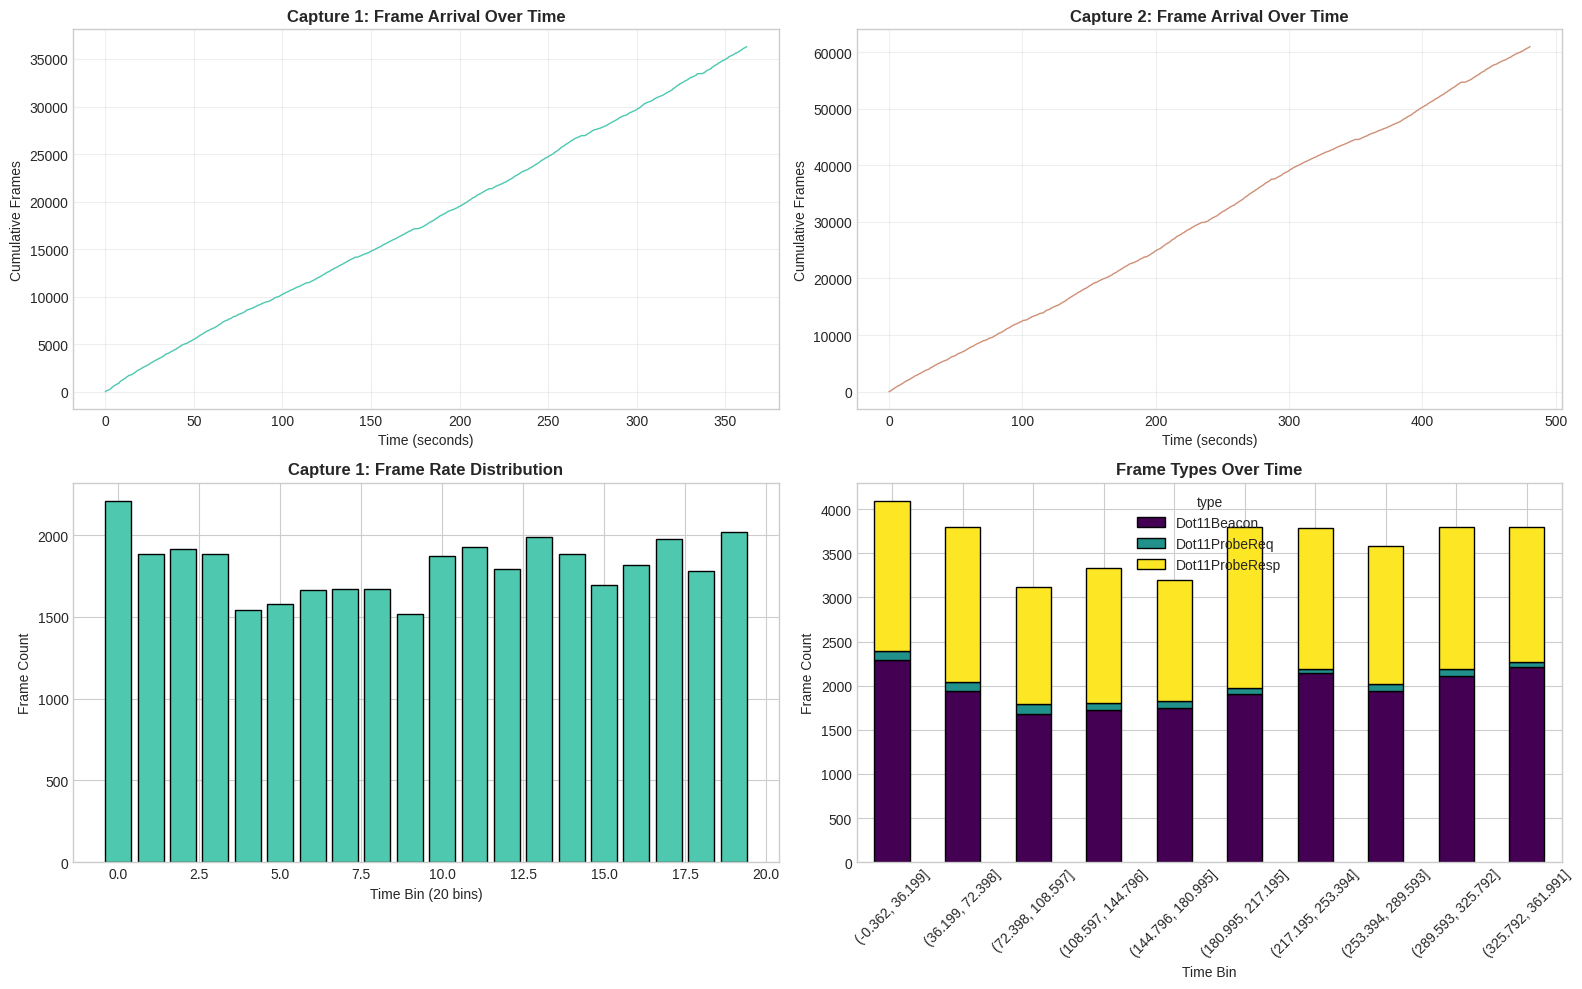

In [6]:
# Time Series Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Convert timestamps to relative seconds
df1_time = df1.copy()
df2_time = df2.copy()
df1_time['time_relative'] = df1_time['Timestamp'] - df1_time['Timestamp'].min()
df2_time['time_relative'] = df2_time['Timestamp'] - df2_time['Timestamp'].min()

# 1. Frame arrival over time - Capture 1
ax1 = axes[0, 0]
df1_sorted = df1_time.sort_values('time_relative')
df1_sorted['frame_num'] = range(len(df1_sorted))
ax1.plot(df1_sorted['time_relative'], df1_sorted['frame_num'], color=COLORS['primary'], linewidth=1)
ax1.set_xlabel('Time (seconds)')
ax1.set_ylabel('Cumulative Frames')
ax1.set_title('Capture 1: Frame Arrival Over Time', fontweight='bold')
ax1.grid(True, alpha=0.3)

# 2. Frame arrival over time - Capture 2
ax2 = axes[0, 1]
df2_sorted = df2_time.sort_values('time_relative')
df2_sorted['frame_num'] = range(len(df2_sorted))
ax2.plot(df2_sorted['time_relative'], df2_sorted['frame_num'], color=COLORS['secondary'], linewidth=1)
ax2.set_xlabel('Time (seconds)')
ax2.set_ylabel('Cumulative Frames')
ax2.set_title('Capture 2: Frame Arrival Over Time', fontweight='bold')
ax2.grid(True, alpha=0.3)

# 3. Frame rate over time (binned)
ax3 = axes[1, 0]
bins = pd.cut(df1_time['time_relative'], bins=20)
frame_rate = df1_time.groupby(bins).size()
ax3.bar(range(len(frame_rate)), frame_rate.values, color=COLORS['primary'], edgecolor='black')
ax3.set_xlabel('Time Bin (20 bins)')
ax3.set_ylabel('Frame Count')
ax3.set_title('Capture 1: Frame Rate Distribution', fontweight='bold')

# 4. Frame type distribution over time
ax4 = axes[1, 1]
bins = pd.cut(df1_time['time_relative'], bins=10)
frame_type_time = df1_time.groupby([bins, 'type']).size().unstack(fill_value=0)
frame_type_time.plot(kind='bar', stacked=True, ax=ax4, colormap='viridis', edgecolor='black')
ax4.set_xlabel('Time Bin')
ax4.set_ylabel('Frame Count')
ax4.set_title('Frame Types Over Time', fontweight='bold')
ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('time_series_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.3 Network Activity Visualization

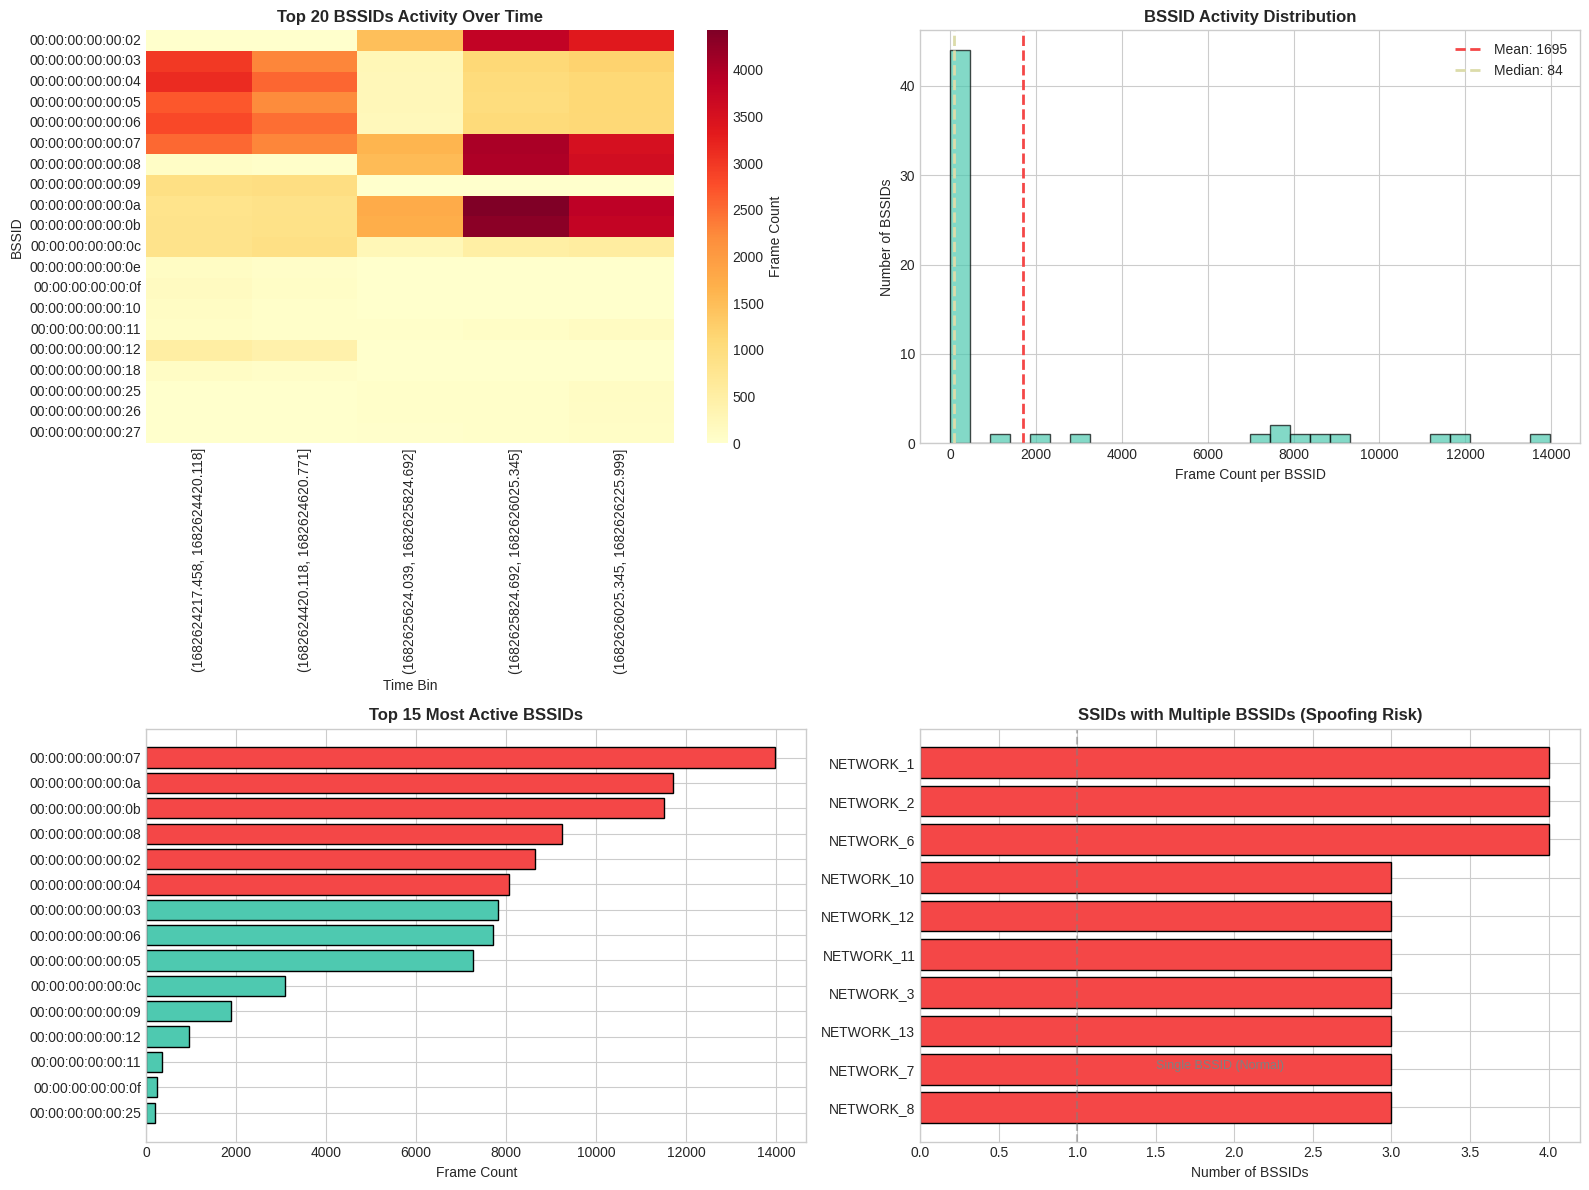

In [7]:
# Network Activity Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. BSSID Activity Heatmap
ax1 = axes[0, 0]
top_bssids = ap_frames['addr2'].value_counts().head(20).index
top_frames = ap_frames[ap_frames['addr2'].isin(top_bssids)].copy()
top_frames['time_bin'] = pd.cut(top_frames['Timestamp'], bins=10)
heatmap_data = top_frames.pivot_table(values='rssi', index='addr2', columns='time_bin', aggfunc='count', fill_value=0)
sns.heatmap(heatmap_data, cmap='YlOrRd', ax=ax1, cbar_kws={'label': 'Frame Count'})
ax1.set_title('Top 20 BSSIDs Activity Over Time', fontweight='bold')
ax1.set_xlabel('Time Bin')
ax1.set_ylabel('BSSID')

# 2. BSSID Frame Count Distribution
ax2 = axes[0, 1]
bssid_counts = ap_frames['addr2'].value_counts()
ax2.hist(bssid_counts.values, bins=30, color=COLORS['primary'], edgecolor='black', alpha=0.7)
ax2.axvline(bssid_counts.mean(), color=COLORS['danger'], linestyle='--', linewidth=2,
            label=f'Mean: {bssid_counts.mean():.0f}')
ax2.axvline(bssid_counts.median(), color=COLORS['warning'], linestyle='--', linewidth=2,
            label=f'Median: {bssid_counts.median():.0f}')
ax2.set_xlabel('Frame Count per BSSID')
ax2.set_ylabel('Number of BSSIDs')
ax2.set_title('BSSID Activity Distribution', fontweight='bold')
ax2.legend()

# 3. Top 15 Most Active BSSIDs
ax3 = axes[1, 0]
top15 = bssid_counts.head(15)
colors = [COLORS['danger'] if c > bssid_counts.quantile(0.9) else COLORS['primary'] for c in top15.values]
ax3.barh(range(len(top15)), top15.values, color=colors, edgecolor='black')
ax3.set_yticks(range(len(top15)))
ax3.set_yticklabels([b[:17] + '...' if len(b) > 17 else b for b in top15.index])
ax3.set_xlabel('Frame Count')
ax3.set_title('Top 15 Most Active BSSIDs', fontweight='bold')
ax3.invert_yaxis()

# 4. SSID vs BSSID relationship
ax4 = axes[1, 1]
ssid_bssid = ap_frames[ap_frames['SSID'] != ''].groupby('SSID')['addr2'].nunique().sort_values(ascending=False).head(10)
colors = [COLORS['danger'] if c > 1 else COLORS['primary'] for c in ssid_bssid.values]
ax4.barh(range(len(ssid_bssid)), ssid_bssid.values, color=colors, edgecolor='black')
ax4.set_yticks(range(len(ssid_bssid)))
ax4.set_yticklabels([s[:15] + '...' if len(s) > 15 else s for s in ssid_bssid.index])
ax4.set_xlabel('Number of BSSIDs')
ax4.set_title('SSIDs with Multiple BSSIDs (Spoofing Risk)', fontweight='bold')
ax4.axvline(1, color='gray', linestyle='--', alpha=0.5)
ax4.annotate('Single BSSID (Normal)', xy=(1.5, 8), fontsize=9, color='gray')
ax4.invert_yaxis()

plt.tight_layout()
plt.savefig('network_activity.png', dpi=150, bbox_inches='tight')
plt.show()

---

# 3. Rule 1: SSID Spoofing Detection

## Description

An **evil twin attack** occurs when a rogue AP broadcasts the same SSID as a legitimate network but with a different BSSID. This rule detects SSIDs that are advertised by multiple distinct BSSIDs.

## Implementation

1. Group frames by SSID
2. Count unique BSSIDs per SSID
3. Flag SSIDs with multiple BSSIDs as potential spoofing

## Threshold

- An SSID is flagged if it has **> 1 unique BSSID**
- Severity: **HIGH** (3 points)

In [8]:
def detect_ssid_spoofing(df):
    """
    Detect SSID Spoofing attacks.
    
    An evil twin attack is detected when the same SSID is advertised
    by multiple distinct BSSIDs.
    
    Returns:
        dict: Findings with spoofed SSIDs and associated BSSIDs
    """
    findings = []
    
    # Group by SSID and count unique BSSIDs
    ssid_bssid = df.groupby('SSID')['addr2'].nunique().reset_index()
    ssid_bssid.columns = ['SSID', 'bssid_count']
    
    # Find SSIDs with multiple BSSIDs (potential spoofing)
    spoofed_ssids = ssid_bssid[ssid_bssid['bssid_count'] > 1]['SSID'].tolist()
    
    for ssid in spoofed_ssids:
        if ssid == '' or ssid == 'b''':
            continue
        
        bssids = df[df['SSID'] == ssid]['addr2'].unique()
        
        findings.append({
            'rule': 'SSID Spoofing',
            'severity': 'HIGH',
            'ssid': ssid,
            'bssids': list(bssids),
            'bssid_count': len(bssids),
            'description': f'SSID "{ssid}" advertised by {len(bssids)} different BSSIDs'
        })
    
    return findings

# Run detection
ssid_findings = detect_ssid_spoofing(ap_frames)
print(f"SSID Spoofing Findings: {len(ssid_findings)}")
print("\nSpoofed SSIDs:")
for f in ssid_findings[:10]:
    print(f"  {f['ssid']}: {f['bssid_count']} BSSIDs - {f['description']}")

SSID Spoofing Findings: 13

Spoofed SSIDs:
  NETWORK_1: 4 BSSIDs - SSID "NETWORK_1" advertised by 4 different BSSIDs
  NETWORK_10: 3 BSSIDs - SSID "NETWORK_10" advertised by 3 different BSSIDs
  NETWORK_11: 3 BSSIDs - SSID "NETWORK_11" advertised by 3 different BSSIDs
  NETWORK_12: 3 BSSIDs - SSID "NETWORK_12" advertised by 3 different BSSIDs
  NETWORK_13: 3 BSSIDs - SSID "NETWORK_13" advertised by 3 different BSSIDs
  NETWORK_2: 4 BSSIDs - SSID "NETWORK_2" advertised by 4 different BSSIDs
  NETWORK_3: 3 BSSIDs - SSID "NETWORK_3" advertised by 3 different BSSIDs
  NETWORK_4: 2 BSSIDs - SSID "NETWORK_4" advertised by 2 different BSSIDs
  NETWORK_5: 2 BSSIDs - SSID "NETWORK_5" advertised by 2 different BSSIDs
  NETWORK_6: 4 BSSIDs - SSID "NETWORK_6" advertised by 4 different BSSIDs


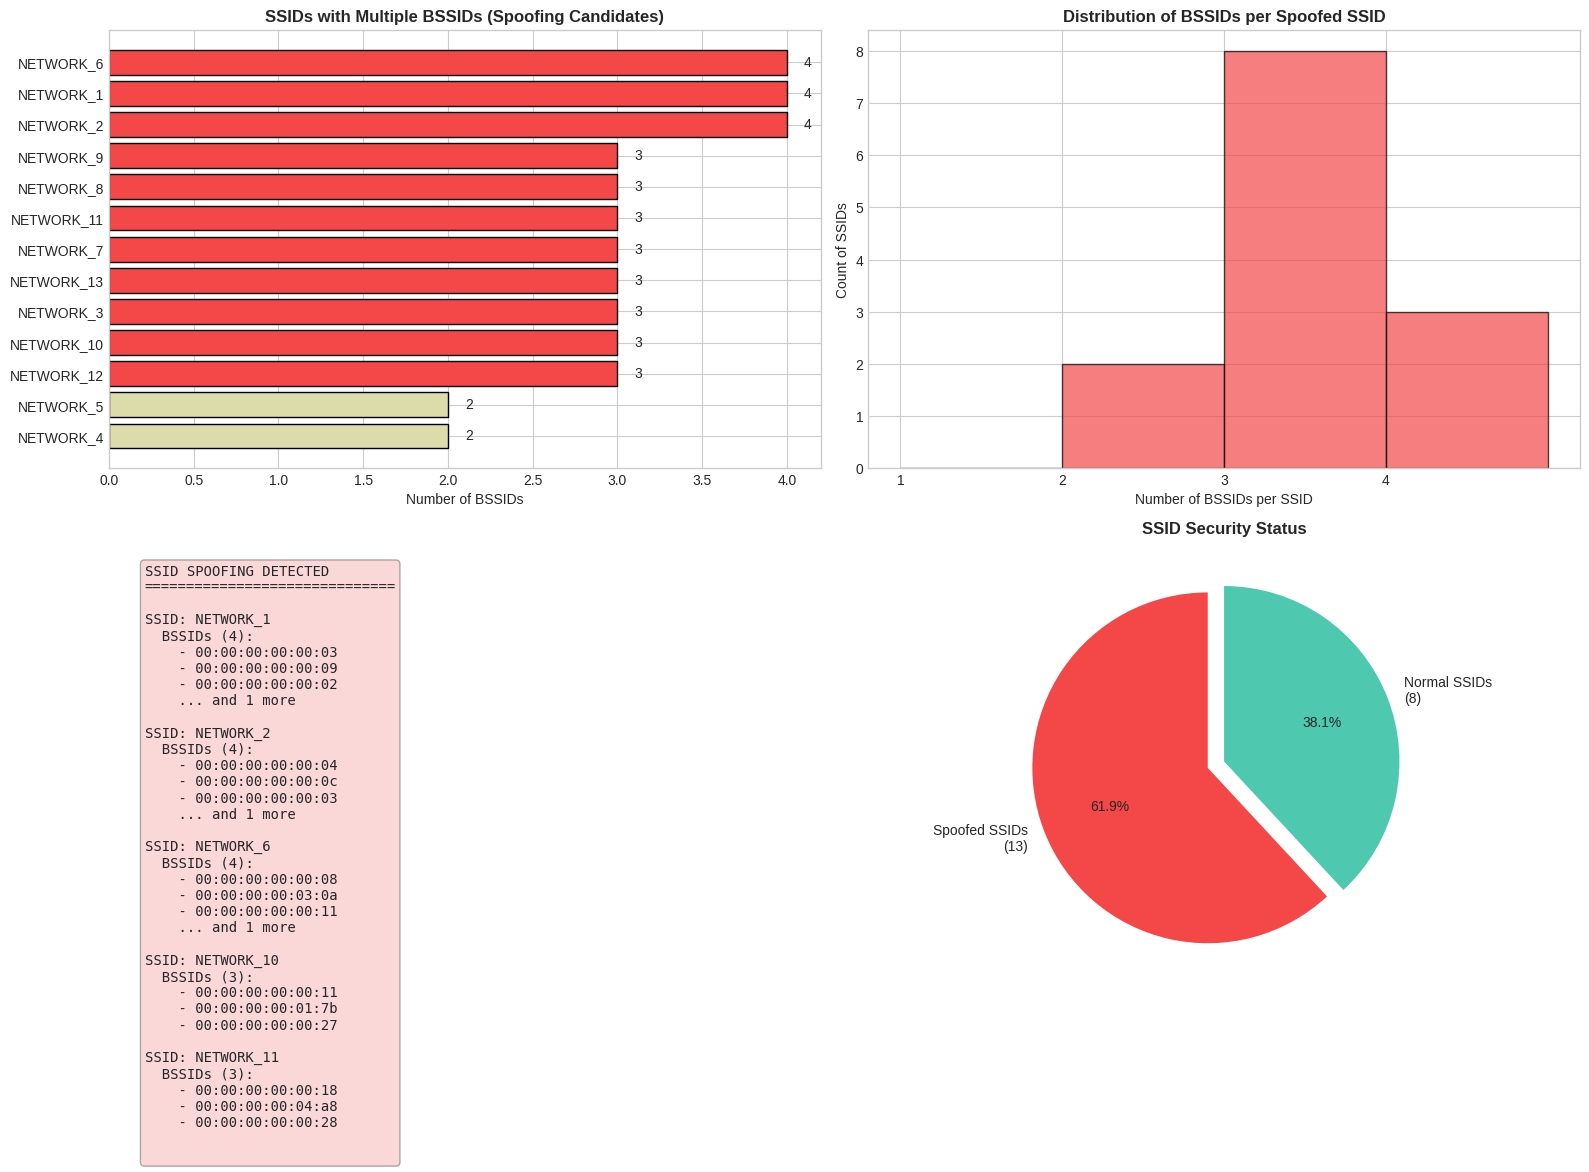

In [9]:
# SSID Spoofing Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. SSID Spoofing Overview - Bar Chart
ax1 = axes[0, 0]
spoof_data = pd.DataFrame(ssid_findings)
if len(spoof_data) > 0:
    spoof_data_sorted = spoof_data.sort_values('bssid_count', ascending=True)
    colors = [COLORS['danger'] if c > 2 else COLORS['warning'] for c in spoof_data_sorted['bssid_count']]
    ax1.barh(range(len(spoof_data_sorted)), spoof_data_sorted['bssid_count'], color=colors, edgecolor='black')
    ax1.set_yticks(range(len(spoof_data_sorted)))
    ax1.set_yticklabels([s[:15] + '...' if len(s) > 15 else s for s in spoof_data_sorted['ssid']])
    ax1.set_xlabel('Number of BSSIDs')
    ax1.set_title('SSIDs with Multiple BSSIDs (Spoofing Candidates)', fontweight='bold')
    for i, (idx, row) in enumerate(spoof_data_sorted.iterrows()):
        ax1.text(row['bssid_count'] + 0.1, i, str(row['bssid_count']), va='center', fontsize=10)

# 2. BSSID Distribution per Spoofed SSID
ax2 = axes[0, 1]
if len(spoof_data) > 0:
    bssid_per_ssid = [len(f['bssids']) for f in ssid_findings]
    ax2.hist(bssid_per_ssid, bins=range(1, max(bssid_per_ssid)+2), color=COLORS['danger'], edgecolor='black', alpha=0.7)
    ax2.set_xlabel('Number of BSSIDs per SSID')
    ax2.set_ylabel('Count of SSIDs')
    ax2.set_title('Distribution of BSSIDs per Spoofed SSID', fontweight='bold')
    ax2.set_xticks(range(1, max(bssid_per_ssid)+1))

# 3. Network Diagram - SSID to BSSID Mapping
ax3 = axes[1, 0]
ax3.axis('off')
if len(ssid_findings) > 0:
    text = "SSID SPOOFING DETECTED\n" + "=" * 30 + "\n\n"
    for f in sorted(ssid_findings, key=lambda x: -x['bssid_count'])[:5]:
        text += f"SSID: {f['ssid']}\n"
        text += f"  BSSIDs ({f['bssid_count']}):\n"
        for b in f['bssids'][:3]:
            text += f"    - {b}\n"
        if len(f['bssids']) > 3:
            text += f"    ... and {len(f['bssids'])-3} more\n"
        text += "\n"
    ax3.text(0.05, 0.95, text, transform=ax3.transAxes, fontsize=10,
             verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.3))

# 4. Risk Assessment Pie Chart
ax4 = axes[1, 1]
spoofed = len(ssid_findings)
normal = len(ap_frames['SSID'].unique()) - spoofed
labels = [f'Spoofed SSIDs\n({spoofed})', f'Normal SSIDs\n({normal})']
colors = [COLORS['danger'], COLORS['safe']]
ax4.pie([spoofed, normal], labels=labels, colors=colors, autopct='%1.1f%%', 
        startangle=90, explode=[0.1, 0])
ax4.set_title('SSID Security Status', fontweight='bold')

plt.tight_layout()
plt.savefig('ssid_spoofing_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---

# 4. Rule 2: MAC Address Inconsistency Detection

## Description

According to IEEE 802.11 specification, in management frames (Beacon, Probe Response), the **Source Address (addr2)** and **BSSID (addr3)** must be identical. Frame injection attacks often have mismatched addresses.

## Implementation

1. Filter to Beacon and Probe Response frames
2. Compare addr2 and addr3 fields
3. Flag frames where addr2 ≠ addr3

## Threshold

- Severity: **HIGH** (3 points) per frame

In [10]:
def detect_mac_inconsistency(df):
    """
    Detect MAC Address Inconsistency.
    
    In IEEE 802.11 management frames, addr2 (Source Address) 
    must equal addr3 (BSSID). Mismatch indicates frame injection.
    
    Returns:
        dict: Findings with inconsistent frames
    """
    findings = []
    
    # Filter to management frames
    mgmt_frames = df[df['type'].isin(['Dot11Beacon', 'Dot11ProbeResp'])].copy()
    
    # Find inconsistent frames
    inconsistent = mgmt_frames[mgmt_frames['addr2'] != mgmt_frames['addr3']]
    
    for _, row in inconsistent.iterrows():
        findings.append({
            'rule': 'MAC Inconsistency',
            'severity': 'HIGH',
            'timestamp': row['Timestamp'],
            'frame_type': row['type'],
            'addr1': row['addr1'],
            'addr2': row['addr2'],
            'addr3': row['addr3'],
            'ssid': row['SSID'],
            'description': f'{row["type"]}: addr2 ({row["addr2"]}) ≠ addr3 ({row["addr3"]})'
        })
    
    return findings

# Run detection
mac_findings = detect_mac_inconsistency(df)
print(f"MAC Inconsistency Findings: {len(mac_findings)}")
print(f"\nCompliance Rate: {100 * (len(ap_frames) - len(mac_findings)) / len(ap_frames):.2f}%")

if mac_findings:
    print("\nSample Inconsistent Frames:")
    for f in mac_findings[:5]:
        print(f"  {f['description']}")

MAC Inconsistency Findings: 0

Compliance Rate: 100.00%


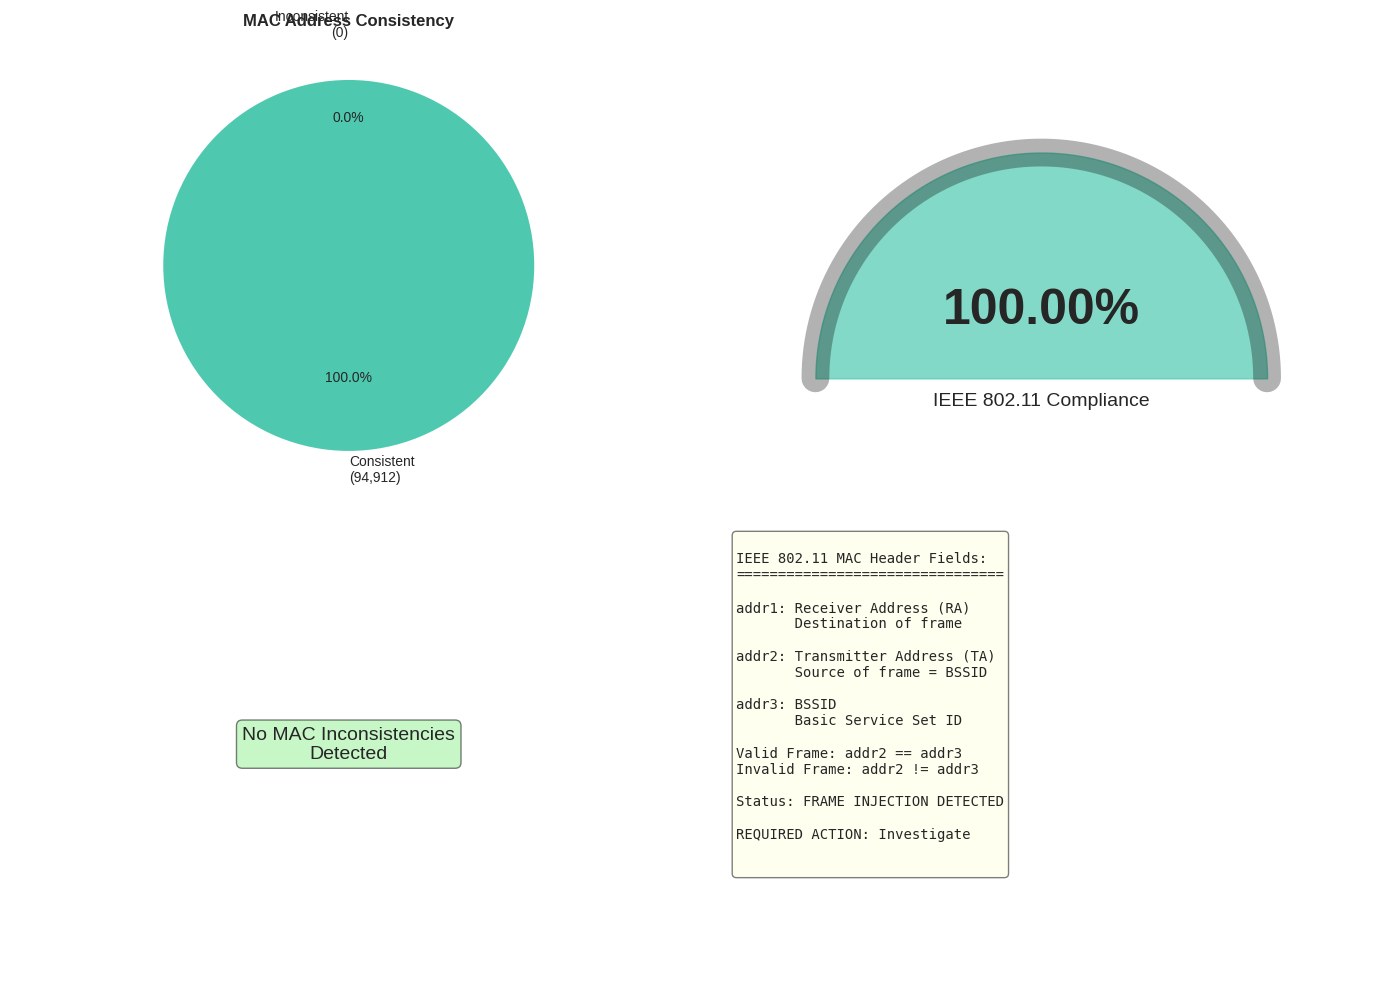

In [11]:
# MAC Consistency Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Compliance Pie Chart
ax1 = axes[0, 0]
consistent = len(ap_frames) - len(mac_findings)
inconsistent = len(mac_findings)
colors = [COLORS['safe'], COLORS['danger']]
labels = [f'Consistent\n({consistent:,})', f'Inconsistent\n({inconsistent})']
ax1.pie([consistent, inconsistent], labels=labels, colors=colors, autopct='%1.1f%%', 
        startangle=90, explode=[0, 0.2])
ax1.set_title('MAC Address Consistency', fontweight='bold')

# 2. Compliance Gauge
ax2 = axes[0, 1]
compliance_rate = 100 * consistent / len(ap_frames)
ax2.axis('off')
# Create a semi-circular gauge
theta = np.linspace(0, np.pi, 100)
r = 1
ax2.plot(r * np.cos(theta), r * np.sin(theta), 'k-', linewidth=20, alpha=0.3)

# Fill based on compliance
angle = np.pi * (1 - compliance_rate/100)
ax2.fill_between(r * np.cos(theta[theta >= angle]), 0, r * np.sin(theta[theta >= angle]), 
                color=COLORS['safe'], alpha=0.7)
ax2.text(0, 0.3, f'{compliance_rate:.2f}%', fontsize=36, ha='center', va='center', fontweight='bold')
ax2.text(0, -0.1, 'IEEE 802.11 Compliance', fontsize=14, ha='center', va='center')
ax2.set_xlim(-1.5, 1.5)
ax2.set_ylim(-0.5, 1.5)
ax2.set_aspect('equal')
ax2.axis('off')

# 3. Frame Types with Inconsistencies (if any)
ax3 = axes[1, 0]
if mac_findings:
    mac_df = pd.DataFrame(mac_findings)
    type_counts = mac_df['frame_type'].value_counts()
    ax3.bar(type_counts.index, type_counts.values, color=COLORS['danger'], edgecolor='black')
    ax3.set_xlabel('Frame Type')
    ax3.set_ylabel('Inconsistent Frame Count')
    ax3.set_title('Inconsistencies by Frame Type', fontweight='bold')
else:
    ax3.text(0.5, 0.5, 'No MAC Inconsistencies\nDetected', ha='center', va='center', 
             fontsize=14, transform=ax3.transAxes,
             bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
    ax3.axis('off')

# 4. IEEE 802.11 Frame Structure
ax4 = axes[1, 1]
ax4.axis('off')
frame_info = """
IEEE 802.11 MAC Header Fields:
================================

addr1: Receiver Address (RA)
       Destination of frame

addr2: Transmitter Address (TA)
       Source of frame = BSSID

addr3: BSSID
       Basic Service Set ID

Valid Frame: addr2 == addr3
Invalid Frame: addr2 != addr3
                 
Status: FRAME INJECTION DETECTED
        
REQUIRED ACTION: Investigate
                  
"""
ax4.text(0.05, 0.95, frame_info, transform=ax4.transAxes, fontsize=10,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

plt.tight_layout()
plt.savefig('mac_consistency_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---

# 5. Rule 3: RSSI Anomaly Detection

## Description

Signal strength (RSSI) anomalies occur when an AP's signal varies significantly from its normal range. This can indicate:
- AP impersonation at different distance
- Signal interference or reflection attacks
- Hardware issues or environmental changes

## Implementation

### Method 1: Z-Score Analysis
- Calculate per-BSSID RSSI mean and standard deviation
- Flag frames where |z-score| > threshold

### Method 2: Isolation Forest (ML-based)
- Unsupervised anomaly detection algorithm
- Identifies outliers based on feature isolation

## Threshold

- Z-score threshold: **2.5** (flags ~1.2% as outliers)
- Severity: **MEDIUM** (2 points)

In [12]:
def detect_rssi_anomaly_zscore(df, threshold=2.5):
    """
    Detect RSSI anomalies using Z-Score analysis.
    
    For each BSSID, calculate mean and std of RSSI.
    Flag frames where |z-score| > threshold.
    
    Returns:
        dict: Findings with anomalous RSSI frames
    """
    findings = []
    
    # Group by BSSID
    bssid_stats = df.groupby('addr2')['rssi'].agg(['mean', 'std', 'count']).reset_index()
    bssid_stats.columns = ['bssid', 'rssi_mean', 'rssi_std', 'frame_count']
    
    for _, row in df.iterrows():
        bssid = row['addr2']
        rssi = row['rssi']
        
        stats_row = bssid_stats[bssid_stats['bssid'] == bssid]
        if len(stats_row) == 0:
            continue
        
        bssid_mean = stats_row['rssi_mean'].values[0]
        bssid_std = stats_row['rssi_std'].values[0]
        
        if bssid_std > 0:
            z_score = abs((rssi - bssid_mean) / bssid_std)
        else:
            z_score = 0
        
        if z_score > threshold:
            findings.append({
                'rule': 'RSSI Anomaly',
                'severity': 'MEDIUM',
                'timestamp': row['Timestamp'],
                'bssid': bssid,
                'rssi': rssi,
                'bssid_mean': bssid_mean,
                'bssid_std': bssid_std,
                'z_score': z_score,
                'description': f'BSSID {bssid}: RSSI {rssi} (z={z_score:.2f})'
            })
    
    return findings

# Run detection
rssi_findings = detect_rssi_anomaly_zscore(ap_frames, threshold=2.5)
print(f"RSSI Anomaly Findings: {len(rssi_findings)}")
print(f"Anomaly Rate: {100 * len(rssi_findings) / len(ap_frames):.2f}%")

# Per-BSSID statistics
bssid_rssi = ap_frames.groupby('addr2')['rssi'].agg(['mean', 'std']).reset_index()
bssid_rssi = bssid_rssi[bssid_rssi['std'] > 0].sort_values('std', ascending=False)

print("\nTop 5 BSSIDs with Highest RSSI Variance:")
for _, row in bssid_rssi.head(5).iterrows():
    print(f"  {row['addr2']}: mean={row['mean']:.1f}, std={row['std']:.1f}")

RSSI Anomaly Findings: 877
Anomaly Rate: 0.92%

Top 5 BSSIDs with Highest RSSI Variance:
  00:00:00:00:00:03: mean=-58.1, std=9.7
  00:00:00:00:00:05: mean=-58.1, std=9.7
  00:00:00:00:00:06: mean=-57.9, std=9.5
  00:00:00:00:00:04: mean=-57.5, std=9.5
  00:00:00:00:00:0b: mean=-56.4, std=6.3


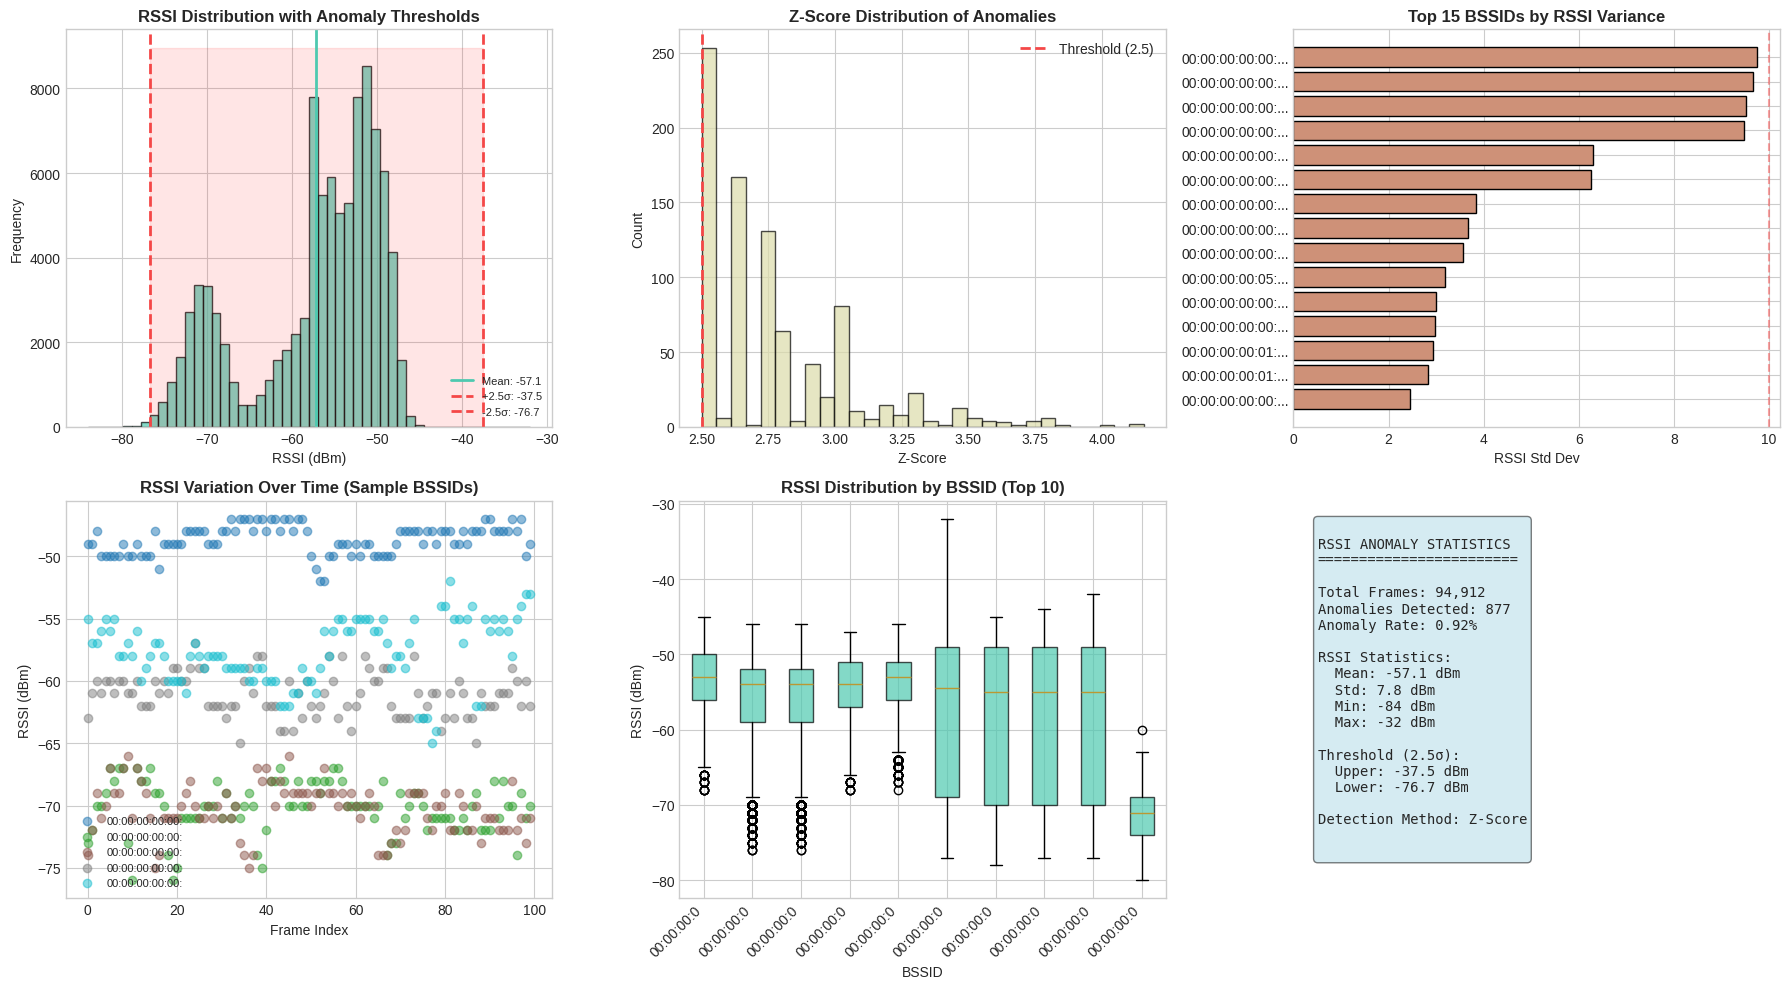

In [13]:
# RSSI Anomaly Visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. RSSI Distribution with Anomaly Threshold
ax1 = axes[0, 0]
rssi_mean = ap_frames['rssi'].mean()
rssi_std = ap_frames['rssi'].std()
threshold = 2.5 * rssi_std

ax1.hist(ap_frames['rssi'], bins=50, edgecolor='black', alpha=0.7, color=COLORS['primary'])
ax1.axvline(rssi_mean, color=COLORS['safe'], linestyle='-', linewidth=2, label=f'Mean: {rssi_mean:.1f}')
ax1.axvline(rssi_mean + threshold, color=COLORS['danger'], linestyle='--', linewidth=2, label=f'+2.5σ: {rssi_mean + threshold:.1f}')
ax1.axvline(rssi_mean - threshold, color=COLORS['danger'], linestyle='--', linewidth=2, label=f'-2.5σ: {rssi_mean - threshold:.1f}')
ax1.fill_betweenx([0, ax1.get_ylim()[1]], rssi_mean + threshold, rssi_mean - threshold, alpha=0.1, color='red')
ax1.set_xlabel('RSSI (dBm)')
ax1.set_ylabel('Frequency')
ax1.set_title('RSSI Distribution with Anomaly Thresholds', fontweight='bold')
ax1.legend(fontsize=8)

# 2. Z-Score Distribution
ax2 = axes[0, 1]
if rssi_findings:
    z_scores = [f['z_score'] for f in rssi_findings]
    ax2.hist(z_scores, bins=30, edgecolor='black', alpha=0.7, color=COLORS['warning'])
    ax2.axvline(2.5, color=COLORS['danger'], linestyle='--', linewidth=2, label='Threshold (2.5)')
    ax2.set_xlabel('Z-Score')
    ax2.set_ylabel('Count')
    ax2.set_title('Z-Score Distribution of Anomalies', fontweight='bold')
    ax2.legend()

# 3. Per-BSSID RSSI Variance
ax3 = axes[0, 2]
top_variance = bssid_rssi.head(15)
ax3.barh(range(len(top_variance)), top_variance['std'].values, color=COLORS['secondary'], edgecolor='black')
ax3.set_yticks(range(len(top_variance)))
ax3.set_yticklabels([b[:15] + '...' if len(b) > 15 else b for b in top_variance['addr2']])
ax3.set_xlabel('RSSI Std Dev')
ax3.set_title('Top 15 BSSIDs by RSSI Variance', fontweight='bold')
ax3.axvline(10, color=COLORS['danger'], linestyle='--', alpha=0.5, label='High Variance Threshold')
ax3.invert_yaxis()

# 4. Scatter: RSSI vs Frame Index (per BSSID)
ax4 = axes[1, 0]
sample_bssids = ap_frames['addr2'].value_counts().head(5).index
colors = plt.cm.tab10(np.linspace(0, 1, 5))
for i, bssid in enumerate(sample_bssids):
    bssid_frames = ap_frames[ap_frames['addr2'] == bssid].head(100)
    ax4.scatter(range(len(bssid_frames)), bssid_frames['rssi'].values, 
                alpha=0.5, label=bssid[:15], color=colors[i])
ax4.set_xlabel('Frame Index')
ax4.set_ylabel('RSSI (dBm)')
ax4.set_title('RSSI Variation Over Time (Sample BSSIDs)', fontweight='bold')
ax4.legend(fontsize=8, loc='lower left')

# 5. Box Plot: RSSI by BSSID (Top 10)
ax5 = axes[1, 1]
top10_bssids = ap_frames['addr2'].value_counts().head(10).index
box_data = [ap_frames[ap_frames['addr2'] == b]['rssi'].values for b in top10_bssids]
bp = ax5.boxplot(box_data, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor(COLORS['primary'])
    patch.set_alpha(0.7)
ax5.set_xticklabels([b[:10] for b in top10_bssids], rotation=45, ha='right')
ax5.set_xlabel('BSSID')
ax5.set_ylabel('RSSI (dBm)')
ax5.set_title('RSSI Distribution by BSSID (Top 10)', fontweight='bold')

# 6. RSSI Anomaly Statistics
ax6 = axes[1, 2]
ax6.axis('off')
stats_text = f"""
RSSI ANOMALY STATISTICS
========================

Total Frames: {len(ap_frames):,}
Anomalies Detected: {len(rssi_findings):,}
Anomaly Rate: {100*len(rssi_findings)/len(ap_frames):.2f}%

RSSI Statistics:
  Mean: {rssi_mean:.1f} dBm
  Std: {rssi_std:.1f} dBm
  Min: {ap_frames['rssi'].min()} dBm
  Max: {ap_frames['rssi'].max()} dBm

Threshold (2.5σ):
  Upper: {rssi_mean + threshold:.1f} dBm
  Lower: {rssi_mean - threshold:.1f} dBm

Detection Method: Z-Score
                    
"""
ax6.text(0.05, 0.95, stats_text, transform=ax6.transAxes, fontsize=10,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

plt.tight_layout()
plt.savefig('rssi_anomaly_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

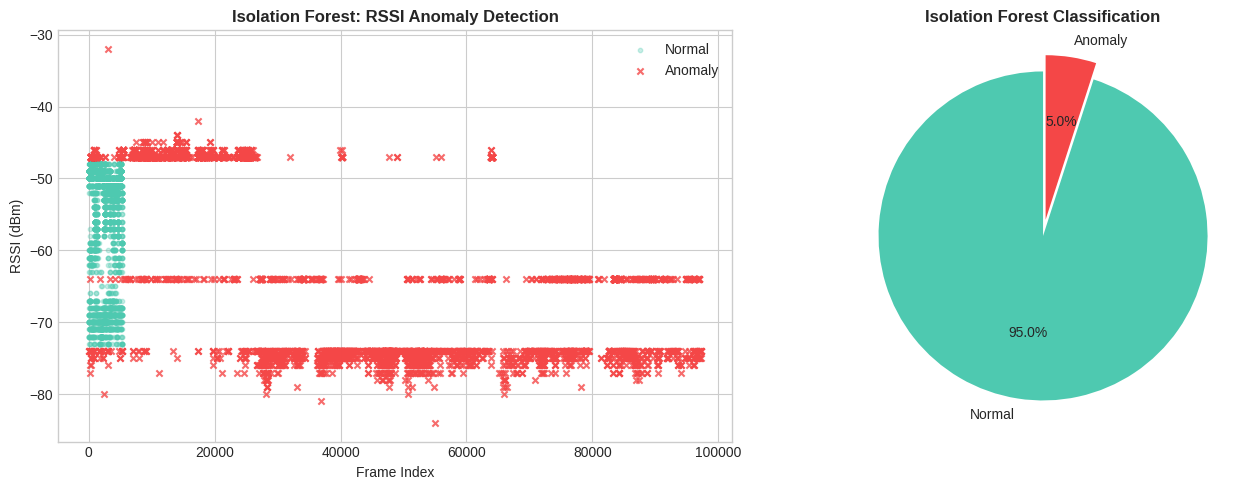

Isolation Forest Anomalies: 4716 (4.97%)


In [14]:
# Isolation Forest Visualization
from sklearn.ensemble import IsolationForest

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Prepare features
features = ap_frames[['rssi']].copy()

# Train Isolation Forest
iso_forest = IsolationForest(
    contamination=0.05,
    random_state=42,
    n_estimators=100
)

# Fit and predict
ap_frames_copy = ap_frames.copy()
ap_frames_copy['anomaly_score'] = iso_forest.fit_predict(features)
ap_frames_copy['anomaly_label'] = ap_frames_copy['anomaly_score'].map({1: 'normal', -1: 'anomaly'})

# 1. Scatter plot
ax1 = axes[0]
normal = ap_frames_copy[ap_frames_copy['anomaly_label'] == 'normal']
anomaly = ap_frames_copy[ap_frames_copy['anomaly_label'] == 'anomaly']

ax1.scatter(normal.index[:5000], normal['rssi'].values[:5000], 
            alpha=0.3, label='Normal', color=COLORS['safe'], s=10)
ax1.scatter(anomaly.index, anomaly['rssi'].values, 
            alpha=0.8, label='Anomaly', color=COLORS['danger'], s=20, marker='x')
ax1.set_xlabel('Frame Index')
ax1.set_ylabel('RSSI (dBm)')
ax1.set_title('Isolation Forest: RSSI Anomaly Detection', fontweight='bold')
ax1.legend()

# 2. Pie chart of results
ax2 = axes[1]
anomaly_counts = ap_frames_copy['anomaly_label'].value_counts()
colors = [COLORS['safe'], COLORS['danger']]
ax2.pie(anomaly_counts.values, labels=anomaly_counts.index.str.title(), 
        colors=colors, autopct='%1.1f%%', startangle=90, explode=[0, 0.1])
ax2.set_title('Isolation Forest Classification', fontweight='bold')

plt.tight_layout()
plt.savefig('isolation_forest_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Isolation Forest Anomalies: {len(anomaly)} ({100 * len(anomaly) / len(ap_frames):.2f}%)")

---

# 6. Rule 4: Probe Response Flood Detection

## Description

A **honeypot AP** may flood the network with excessive Probe Response frames to:
- Confuse clients trying to connect
- Perform denial of service attacks
- Attract clients to connect to the malicious AP

## Threshold

- If BSSID sends **> 3 Probe Responses**: suspicious
- Severity: **LOW** (1 point)

In [15]:
def detect_probe_flood(df, threshold=3):
    """
    Detect Probe Response Flood attacks (Honeypot Detection).
    
    BSSIDs that send excessive Probe Response frames may be
    honeypot access points attempting to attract clients.
    
    Returns:
        dict: Findings with flooding BSSIDs
    """
    findings = []
    
    # Filter to Probe Response frames
    probe_resp = df[df['type'] == 'Dot11ProbeResp']
    
    # Count frames per BSSID
    bssid_counts = probe_resp.groupby('addr2').size().reset_index(name='count')
    
    # Find flooding BSSIDs
    flooding = bssid_counts[bssid_counts['count'] > threshold]
    
    for _, row in flooding.iterrows():
        bssid = row['addr2']
        count = row['count']
        ssids = probe_resp[probe_resp['addr2'] == bssid]['SSID'].unique()
        
        findings.append({
            'rule': 'Probe Response Flood',
            'severity': 'LOW',
            'bssid': bssid,
            'frame_count': count,
            'ssids': list(ssids),
            'description': f'BSSID {bssid} sent {count} Probe Responses'
        })
    
    return findings

# Run detection
probe_findings = detect_probe_flood(df, threshold=3)
print(f"Probe Response Flood Findings: {len(probe_findings)}")

# Distribution
probe_counts = df[df['type'] == 'Dot11ProbeResp'].groupby('addr2').size().sort_values(ascending=False)
print(f"\nProbe Response Distribution:")
print(f"  Min: {probe_counts.min()}")
print(f"  Max: {probe_counts.max()}")
print(f"  Mean: {probe_counts.mean():.1f}")
print(f"  Median: {probe_counts.median():.1f}")

Probe Response Flood Findings: 34

Probe Response Distribution:
  Min: 1
  Max: 8337
  Mean: 1026.9
  Median: 47.5


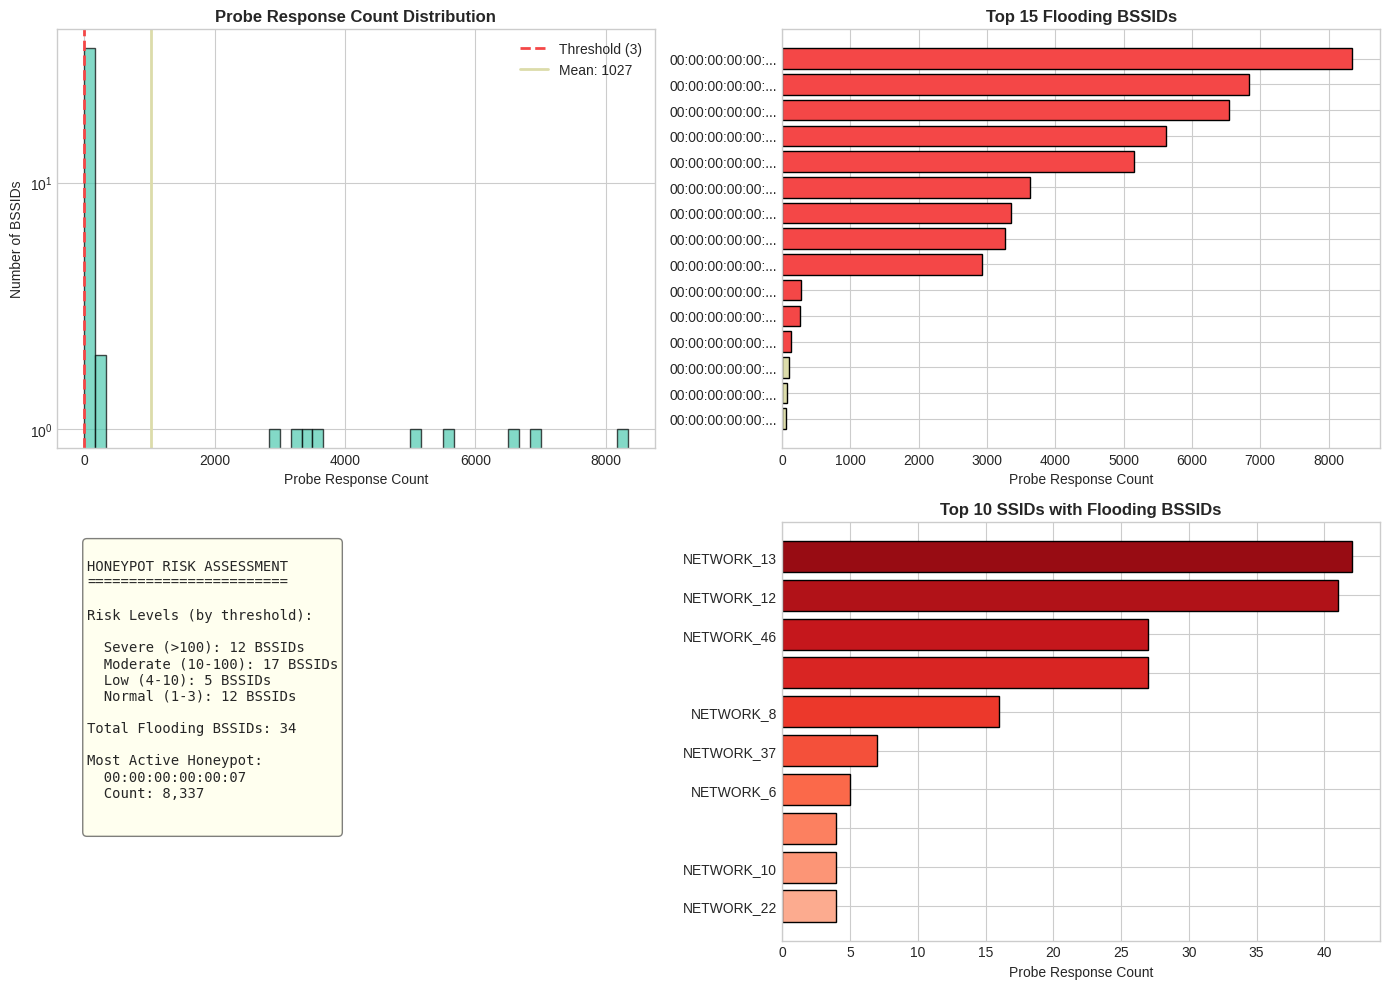

In [16]:
# Probe Response Flood Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Probe Response Count Distribution
ax1 = axes[0, 0]
ax1.hist(probe_counts.values, bins=50, edgecolor='black', alpha=0.7, color=COLORS['primary'])
ax1.axvline(3, color=COLORS['danger'], linestyle='--', linewidth=2, label='Threshold (3)')
ax1.axvline(probe_counts.mean(), color=COLORS['warning'], linestyle='-', linewidth=2, label=f'Mean: {probe_counts.mean():.0f}')
ax1.set_xlabel('Probe Response Count')
ax1.set_ylabel('Number of BSSIDs')
ax1.set_title('Probe Response Count Distribution', fontweight='bold')
ax1.legend()
ax1.set_yscale('log')

# 2. Top Flooding BSSIDs
ax2 = axes[0, 1]
top_flooding = probe_counts.head(15)
colors = [COLORS['danger'] if c > 100 else COLORS['warning'] if c > 10 else COLORS['primary'] for c in top_flooding.values]
ax2.barh(range(len(top_flooding)), top_flooding.values, color=colors, edgecolor='black')
ax2.set_yticks(range(len(top_flooding)))
ax2.set_yticklabels([f'{b[:15]}...' if len(b) > 15 else b for b in top_flooding.index])
ax2.set_xlabel('Probe Response Count')
ax2.set_title('Top 15 Flooding BSSIDs', fontweight='bold')
ax2.invert_yaxis()

# 3. Risk Assessment
ax3 = axes[1, 0]
ax3.axis('off')

# Calculate risk levels
severe = len(probe_counts[probe_counts > 100])
moderate = len(probe_counts[(probe_counts > 10) & (probe_counts <= 100)])
low = len(probe_counts[(probe_counts > 3) & (probe_counts <= 10)])
normal = len(probe_counts[probe_counts <= 3])

risk_text = f"""
HONEYPOT RISK ASSESSMENT
========================

Risk Levels (by threshold):

  Severe (>100): {severe} BSSIDs
  Moderate (10-100): {moderate} BSSIDs
  Low (4-10): {low} BSSIDs
  Normal (1-3): {normal} BSSIDs

Total Flooding BSSIDs: {len(probe_findings)}

Most Active Honeypot:
  {probe_counts.index[0][:20]}
  Count: {probe_counts.values[0]:,}
                    
"""
ax3.text(0.05, 0.95, risk_text, transform=ax3.transAxes, fontsize=10,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

# 4. Stacked Bar - SSIDs with Flooding
ax4 = axes[1, 1]
if probe_findings:
    probe_df = pd.DataFrame(probe_findings)
    probe_df_sorted = probe_df.sort_values('frame_count', ascending=True).head(10)
    
    y_pos = range(len(probe_df_sorted))
    colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(probe_df_sorted)))
    ax4.barh(y_pos, probe_df_sorted['frame_count'], color=colors, edgecolor='black')
    ax4.set_yticks(y_pos)
    ax4.set_yticklabels([s[:15] + '...' if len(s) > 15 else s for s in probe_df_sorted['ssids'].str[0]])
    ax4.set_xlabel('Probe Response Count')
    ax4.set_title('Top 10 SSIDs with Flooding BSSIDs', fontweight='bold')

plt.tight_layout()
plt.savefig('probe_flood_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---

# 7. Rule 5: MAC Timestamp Drift Detection

## Description

Legitimate APs have synchronized internal clocks. The **MAC_timestamp** field in Beacon frames should increase consistently with the wall clock time. Large drift may indicate:
- **Replay attacks**: Old frames being replayed
- **Software-defined APs**: Raspberry Pi or software APs with poor clock synchronization
- **Clock manipulation**: Intentional timestamp spoofing

## Threshold

- Drift > **500ms**: suspicious
- Severity: **LOW** (1 point)

In [17]:
def detect_timestamp_drift(df, threshold_ms=500):
    """
    Detect MAC Timestamp Drift.
    
    Compare MAC_timestamp with wall clock Timestamp.
    Large drift may indicate replay attacks or software APs.
    
    Returns:
        dict: Findings with timestamp drift violations
    """
    findings = []
    drift_samples = []
    
    # Filter to Beacon frames
    beacons = df[df['type'] == 'Dot11Beacon'].copy()
    beacons = beacons.sort_values(['addr2', 'Timestamp'])
    
    for bssid, group in beacons.groupby('addr2'):
        if len(group) < 2:
            continue
        
        timestamps = group['Timestamp'].values
        mac_timestamps = group['MAC_timestamp'].values
        
        for i in range(1, min(len(timestamps), 20)):
            wall_delta = (timestamps[i] - timestamps[i-1]) * 1000
            mac_delta = (mac_timestamps[i] - mac_timestamps[i-1]) / 1000
            
            if wall_delta <= 0:
                continue
            
            drift = abs(mac_delta - wall_delta)
            drift_samples.append({
                'bssid': bssid,
                'frame_index': i,
                'wall_delta_ms': wall_delta,
                'mac_delta_ms': mac_delta,
                'drift_ms': drift
            })
            
            if drift > threshold_ms:
                findings.append({
                    'rule': 'MAC Timestamp Drift',
                    'severity': 'LOW',
                    'bssid': bssid,
                    'frame_index': i,
                    'drift_ms': drift,
                    'description': f'BSSID {bssid}: drift of {drift:.1f}ms'
                })
    
    return findings, drift_samples

# Run detection
drift_findings, drift_samples = detect_timestamp_drift(df, threshold_ms=500)
print(f"MAC Timestamp Drift Findings: {len(drift_findings)}")

if drift_samples:
    drift_df = pd.DataFrame(drift_samples)
    print(f"\nDrift Statistics:")
    print(f"  Mean: {drift_df['drift_ms'].mean():.2f}ms")
    print(f"  Max: {drift_df['drift_ms'].max():.2f}ms")
    print(f"  95th percentile: {drift_df['drift_ms'].quantile(0.95):.2f}ms")

MAC Timestamp Drift Findings: 0

Drift Statistics:
  Mean: 0.03ms
  Max: 1.59ms
  95th percentile: 0.11ms


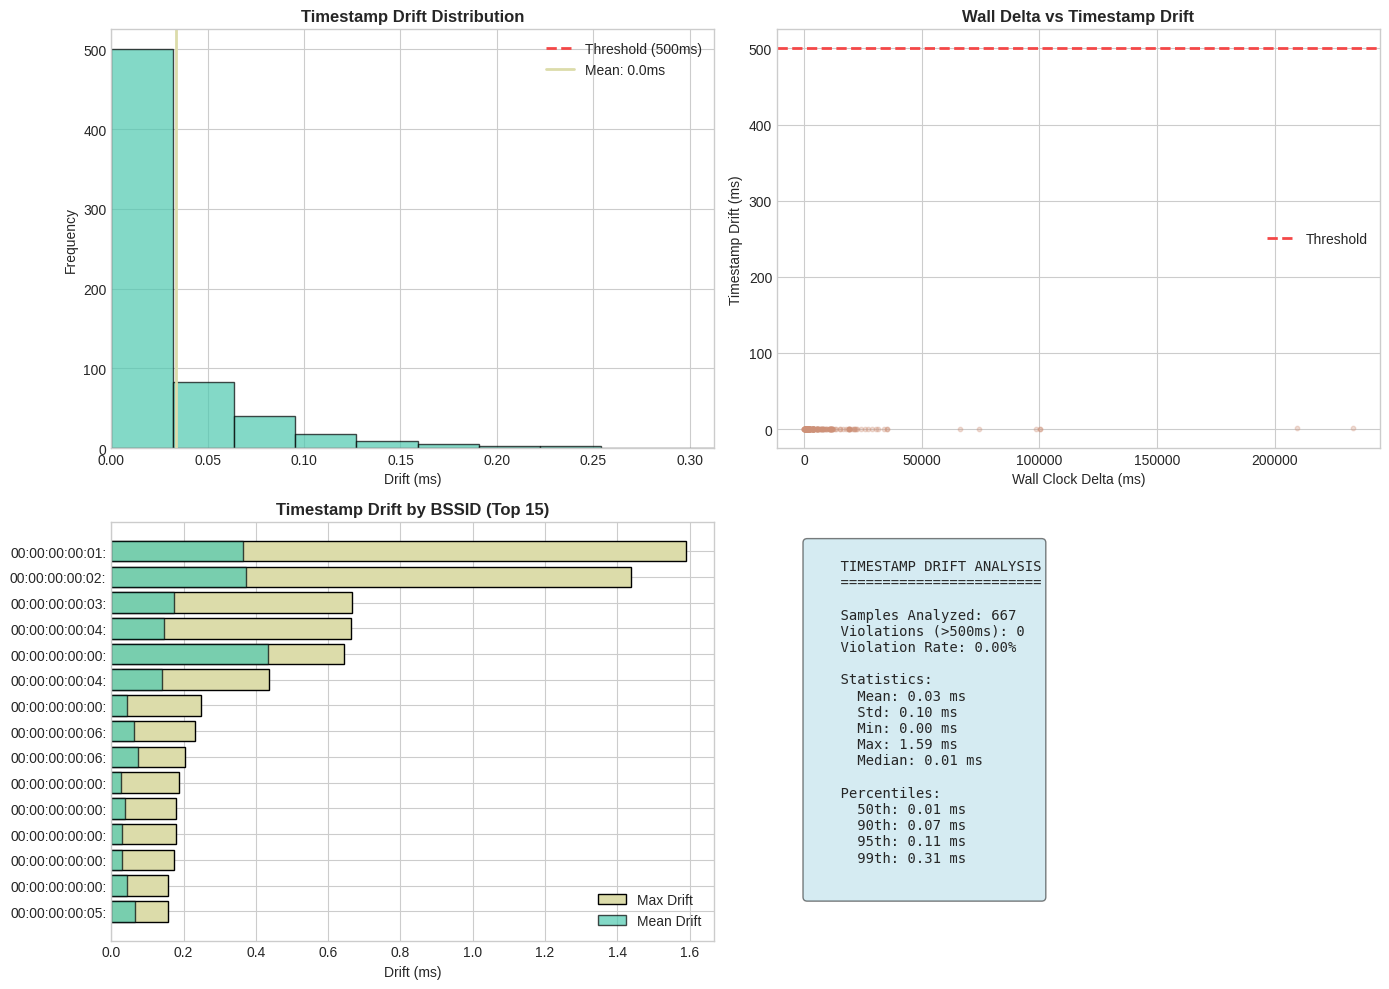

In [18]:
# Timestamp Drift Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

if drift_samples:
    drift_df = pd.DataFrame(drift_samples)
    
    # 1. Drift Distribution Histogram
    ax1 = axes[0, 0]
    ax1.hist(drift_df['drift_ms'], bins=50, edgecolor='black', alpha=0.7, color=COLORS['primary'])
    ax1.axvline(500, color=COLORS['danger'], linestyle='--', linewidth=2, label='Threshold (500ms)')
    ax1.axvline(drift_df['drift_ms'].mean(), color=COLORS['warning'], linestyle='-', linewidth=2, 
                label=f'Mean: {drift_df["drift_ms"].mean():.1f}ms')
    ax1.set_xlabel('Drift (ms)')
    ax1.set_ylabel('Frequency')
    ax1.set_title('Timestamp Drift Distribution', fontweight='bold')
    ax1.set_xlim(0, drift_df['drift_ms'].quantile(0.99))
    ax1.legend()
    
    # 2. Wall Delta vs Drift Scatter
    ax2 = axes[0, 1]
    ax2.scatter(drift_df['wall_delta_ms'], drift_df['drift_ms'], alpha=0.3, s=10, color=COLORS['secondary'])
    ax2.axhline(500, color=COLORS['danger'], linestyle='--', linewidth=2, label='Threshold')
    ax2.set_xlabel('Wall Clock Delta (ms)')
    ax2.set_ylabel('Timestamp Drift (ms)')
    ax2.set_title('Wall Delta vs Timestamp Drift', fontweight='bold')
    ax2.legend()
    
    # 3. Drift by BSSID
    ax3 = axes[1, 0]
    bssid_drift = drift_df.groupby('bssid')['drift_ms'].agg(['mean', 'max']).reset_index()
    bssid_drift_sorted = bssid_drift.sort_values('max', ascending=False).head(15)
    ax3.barh(range(len(bssid_drift_sorted)), bssid_drift_sorted['max'].values, 
            color=COLORS['warning'], edgecolor='black', label='Max Drift')
    ax3.barh(range(len(bssid_drift_sorted)), bssid_drift_sorted['mean'].values, 
            color=COLORS['primary'], edgecolor='black', alpha=0.7, label='Mean Drift')
    ax3.set_yticks(range(len(bssid_drift_sorted)))
    ax3.set_yticklabels([b[:15] for b in bssid_drift_sorted['bssid']])
    ax3.set_xlabel('Drift (ms)')
    ax3.set_title('Timestamp Drift by BSSID (Top 15)', fontweight='bold')
    ax3.legend()
    ax3.invert_yaxis()
    
    # 4. Drift Statistics Summary
    ax4 = axes[1, 1]
    ax4.axis('off')
    stats_text = f"""
    TIMESTAMP DRIFT ANALYSIS
    ========================
    
    Samples Analyzed: {len(drift_df)}
    Violations (>500ms): {len(drift_findings)}
    Violation Rate: {100*len(drift_findings)/len(drift_df):.2f}%
    
    Statistics:
      Mean: {drift_df['drift_ms'].mean():.2f} ms
      Std: {drift_df['drift_ms'].std():.2f} ms
      Min: {drift_df['drift_ms'].min():.2f} ms
      Max: {drift_df['drift_ms'].max():.2f} ms
      Median: {drift_df['drift_ms'].median():.2f} ms
    
    Percentiles:
      50th: {drift_df['drift_ms'].quantile(0.50):.2f} ms
      90th: {drift_df['drift_ms'].quantile(0.90):.2f} ms
      95th: {drift_df['drift_ms'].quantile(0.95):.2f} ms
      99th: {drift_df['drift_ms'].quantile(0.99):.2f} ms
                    
    """
    ax4.text(0.05, 0.95, stats_text, transform=ax4.transAxes, fontsize=10,
             verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
else:
    for ax in axes.flat:
        ax.text(0.5, 0.5, 'No Drift Data Available', ha='center', va='center', 
                fontsize=14, transform=ax.transAxes)
        ax.axis('off')

plt.tight_layout()
plt.savefig('timestamp_drift_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---

# 8. Rule 6: Unknown BSSID Detection

## Description

Unknown BSSIDs are access points that are not in the organization's authorized whitelist. These may be:
- Rogue APs deployed by attackers
- Personal hotspot devices
- Unauthorized network equipment

## Threshold

- Severity: **MEDIUM** (2 points)

In [19]:
def detect_unknown_bssid(df1, df2, whitelist=None):
    """
    Detect Unknown BSSIDs.
    
    BSSIDs not in the authorized whitelist are flagged as unknown.
    For this demo, we use BSSIDs appearing in both captures as whitelist.
    
    Returns:
        dict: Findings with unknown BSSIDs
    """
    findings = []
    
    # For demo: use stable BSSIDs (appear in both captures) as whitelist
    bssids1 = set(df1['addr2'].unique())
    bssids2 = set(df2['addr2'].unique())
    
    if whitelist is None:
        # Stable BSSIDs (appear in both captures)
        whitelist = bssids1 & bssids2
    
    # Find unknown BSSIDs
    all_bssids = set(df1['addr2'].unique()) | set(df2['addr2'].unique())
    unknown_bssids = all_bssids - whitelist
    
    for bssid in unknown_bssids:
        count1 = len(df1[df1['addr2'] == bssid])
        count2 = len(df2[df2['addr2'] == bssid])
        
        ssids = list(set(df1[df1['addr2'] == bssid]['SSID'].unique()) | 
                   set(df2[df2['addr2'] == bssid]['SSID'].unique()))
        
        findings.append({
            'rule': 'Unknown BSSID',
            'severity': 'MEDIUM',
            'bssid': bssid,
            'frames_in_capture1': count1,
            'frames_in_capture2': count2,
            'total_frames': count1 + count2,
            'ssids': [s for s in ssids if s and s != ''],
            'description': f'BSSID {bssid} not in whitelist ({count1 + count2} frames)'
        })
    
    return findings, list(whitelist)

# Run detection
unknown_findings, stable_bssids = detect_unknown_bssid(df1, df2)
print(f"Unknown BSSID Findings: {len(unknown_findings)}")
print(f"Stable BSSIDs (whitelist): {len(stable_bssids)}")

print("\nSample Unknown BSSIDs:")
for f in sorted(unknown_findings, key=lambda x: -x['total_frames'])[:5]:
    print(f"  {f['bssid']}: {f['total_frames']} frames")

Unknown BSSID Findings: 764
Stable BSSIDs (whitelist): 92

Sample Unknown BSSIDs:
  00:00:00:00:00:09: 1890 frames
  00:00:00:00:00:12: 949 frames
  00:00:00:00:01:8d: 273 frames
  00:00:00:00:00:0f: 228 frames
  00:00:00:00:00:26: 181 frames


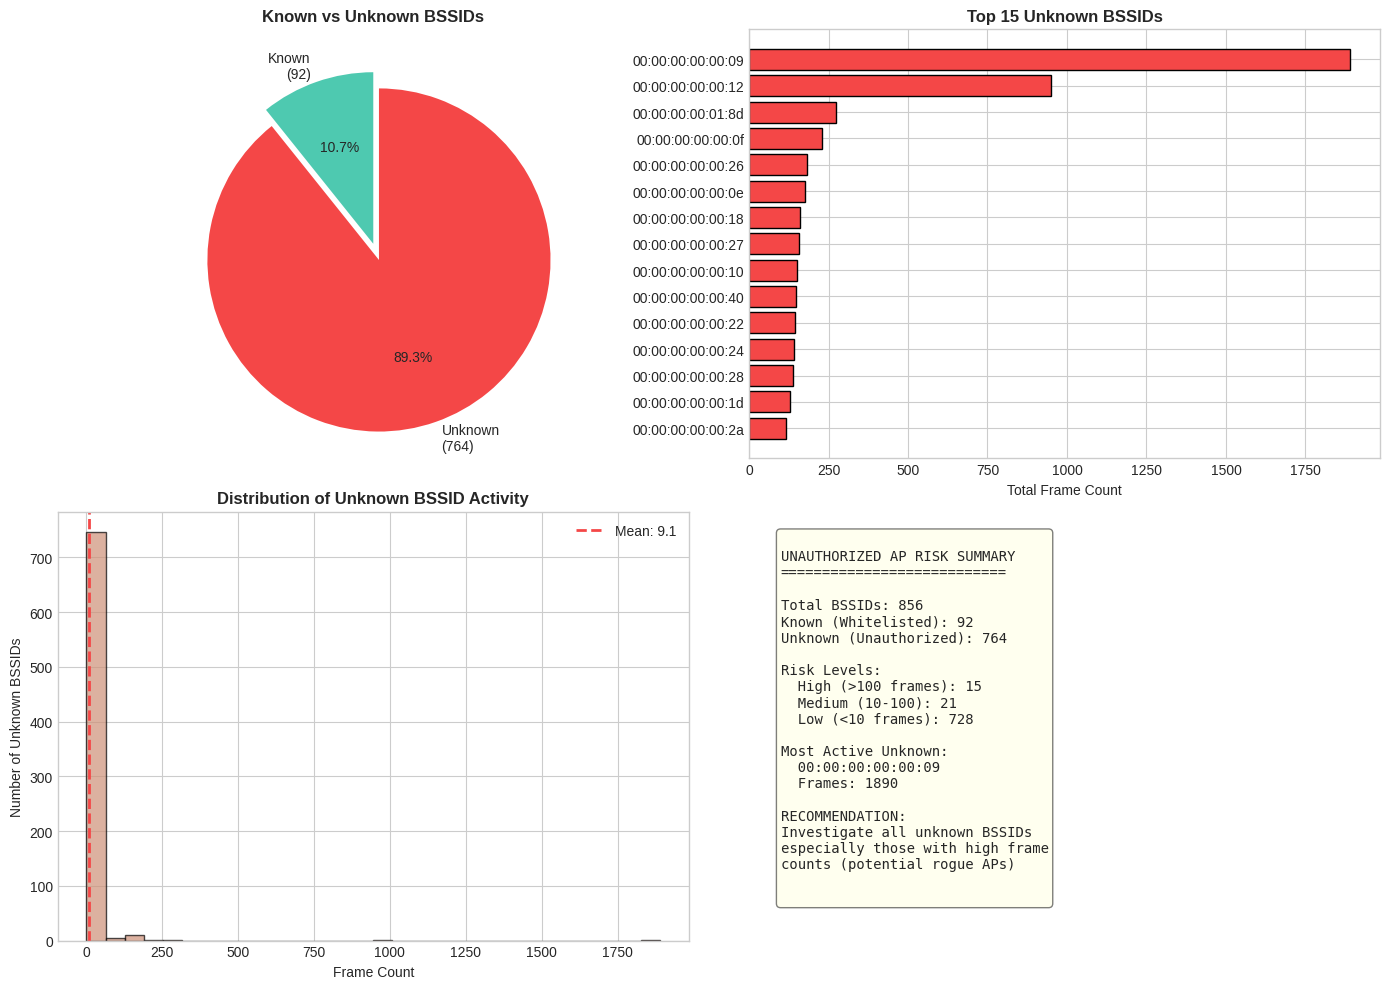

In [20]:
# Unknown BSSID Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Known vs Unknown Pie Chart
ax1 = axes[0, 0]
labels = [f'Known\n({len(stable_bssids)})', f'Unknown\n({len(unknown_findings)})']
colors = [COLORS['safe'], COLORS['danger']]
ax1.pie([len(stable_bssids), len(unknown_findings)], labels=labels, colors=colors, 
        autopct='%1.1f%%', startangle=90, explode=[0, 0.1])
ax1.set_title('Known vs Unknown BSSIDs', fontweight='bold')

# 2. Top Unknown BSSIDs
ax2 = axes[0, 1]
top_unknown = sorted(unknown_findings, key=lambda x: -x['total_frames'])[:15]
frame_counts = [u['total_frames'] for u in top_unknown]
colors = [COLORS['danger'] if c > 100 else COLORS['warning'] if c > 10 else COLORS['primary'] for c in frame_counts]
ax2.barh(range(len(top_unknown)), frame_counts, color=colors, edgecolor='black')
ax2.set_yticks(range(len(top_unknown)))
ax2.set_yticklabels([u['bssid'][:17] + '...' if len(u['bssid']) > 17 else u['bssid'] for u in top_unknown])
ax2.set_xlabel('Total Frame Count')
ax2.set_title('Top 15 Unknown BSSIDs', fontweight='bold')
ax2.invert_yaxis()

# 3. Unknown BSSID Frame Distribution
ax3 = axes[1, 0]
unknown_counts = [u['total_frames'] for u in unknown_findings]
ax3.hist(unknown_counts, bins=30, edgecolor='black', alpha=0.7, color=COLORS['secondary'])
ax3.axvline(np.mean(unknown_counts), color=COLORS['danger'], linestyle='--', linewidth=2, 
            label=f'Mean: {np.mean(unknown_counts):.1f}')
ax3.set_xlabel('Frame Count')
ax3.set_ylabel('Number of Unknown BSSIDs')
ax3.set_title('Distribution of Unknown BSSID Activity', fontweight='bold')
ax3.legend()

# 4. Risk Summary
ax4 = axes[1, 1]
ax4.axis('off')

high_risk = len([u for u in unknown_findings if u['total_frames'] > 100])
medium_risk = len([u for u in unknown_findings if 10 < u['total_frames'] <= 100])
low_risk = len([u for u in unknown_findings if u['total_frames'] <= 10])

risk_text = f"""
UNAUTHORIZED AP RISK SUMMARY
===========================

Total BSSIDs: {len(stable_bssids) + len(unknown_findings)}
Known (Whitelisted): {len(stable_bssids)}
Unknown (Unauthorized): {len(unknown_findings)}

Risk Levels:
  High (>100 frames): {high_risk}
  Medium (10-100): {medium_risk}
  Low (<10 frames): {low_risk}

Most Active Unknown:
  {top_unknown[0]['bssid'][:20] if top_unknown else 'N/A'}
  Frames: {top_unknown[0]['total_frames'] if top_unknown else 0}
                    
RECOMMENDATION:
Investigate all unknown BSSIDs
especially those with high frame
counts (potential rogue APs)
                    
"""
ax4.text(0.05, 0.95, risk_text, transform=ax4.transAxes, fontsize=10,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

plt.tight_layout()
plt.savefig('unknown_bssid_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---

# 9. Scoring and Verdicts

## Scoring System

Each finding contributes points based on severity:

| Severity | Points |
|----------|--------|
| HIGH | 3 |
| MEDIUM | 2 |
| LOW | 1 |

## Verdict Thresholds

| Verdict | Score | Action |
|---------|-------|--------|
| **ROGUE** | ≥ 5 | Immediate investigation |
| **SUSPICIOUS** | ≥ 3 | Monitor closely |
| **LOW RISK** | < 3 | Log for review |

In [21]:
# Severity point mapping
SEVERITY_POINTS = {
    'HIGH': 3,
    'MEDIUM': 2,
    'LOW': 1
}

# Thresholds
ROGUE_THRESHOLD = 5
SUSPICIOUS_THRESHOLD = 3

def calculate_verdict(score):
    """Calculate verdict based on score."""
    if score >= ROGUE_THRESHOLD:
        return 'ROGUE'
    elif score >= SUSPICIOUS_THRESHOLD:
        return 'SUSPICIOUS'
    else:
        return 'LOW RISK'

def aggregate_findings(ssid_findings, mac_findings, rssi_findings, probe_findings, drift_findings, unknown_findings):
    """
    Aggregate all findings by BSSID and calculate scores.
    """
    bssid_scores = {}
    bssid_findings = {}
    
    all_findings = ssid_findings + mac_findings + rssi_findings + probe_findings + drift_findings + unknown_findings
    
    for finding in all_findings:
        bssid = finding.get('bssid') or finding.get('addr2')
        if not bssid:
            continue
        
        severity = finding['severity']
        points = SEVERITY_POINTS.get(severity, 0)
        
        if bssid not in bssid_scores:
            bssid_scores[bssid] = 0
            bssid_findings[bssid] = []
        
        bssid_scores[bssid] += points
        bssid_findings[bssid].append(finding)
    
    # Calculate verdicts
    results = []
    for bssid, score in bssid_scores.items():
        verdict = calculate_verdict(score)
        
        # Get SSIDs for this BSSID
        ssids = ap_frames[ap_frames['addr2'] == bssid]['SSID'].unique()
        ssids = [s for s in ssids if s and s != '']
        
        # Count findings by severity
        finding_counts = {'HIGH': 0, 'MEDIUM': 0, 'LOW': 0}
        for f in bssid_findings[bssid]:
            finding_counts[f['severity']] = finding_counts.get(f['severity'], 0) + 1
        
        results.append({
            'bssid': bssid,
            'score': score,
            'verdict': verdict,
            'ssids': ssids,
            'findings': bssid_findings[bssid],
            'finding_counts': finding_counts
        })
    
    # Sort by score
    results.sort(key=lambda x: -x['score'])
    
    return results

# Aggregate all findings
all_results = aggregate_findings(
    ssid_findings,
    mac_findings,
    rssi_findings,
    probe_findings,
    drift_findings,
    unknown_findings
)

print(f"Total BSSIDs Analyzed: {len(all_results)}")
print(f"\nVerdict Distribution:")
verdict_counts = {}
for r in all_results:
    v = r['verdict']
    verdict_counts[v] = verdict_counts.get(v, 0) + 1

for verdict, count in sorted(verdict_counts.items()):
    print(f"  {verdict}: {count}")

Total BSSIDs Analyzed: 781

Verdict Distribution:
  LOW RISK: 749
  ROGUE: 25
  SUSPICIOUS: 7


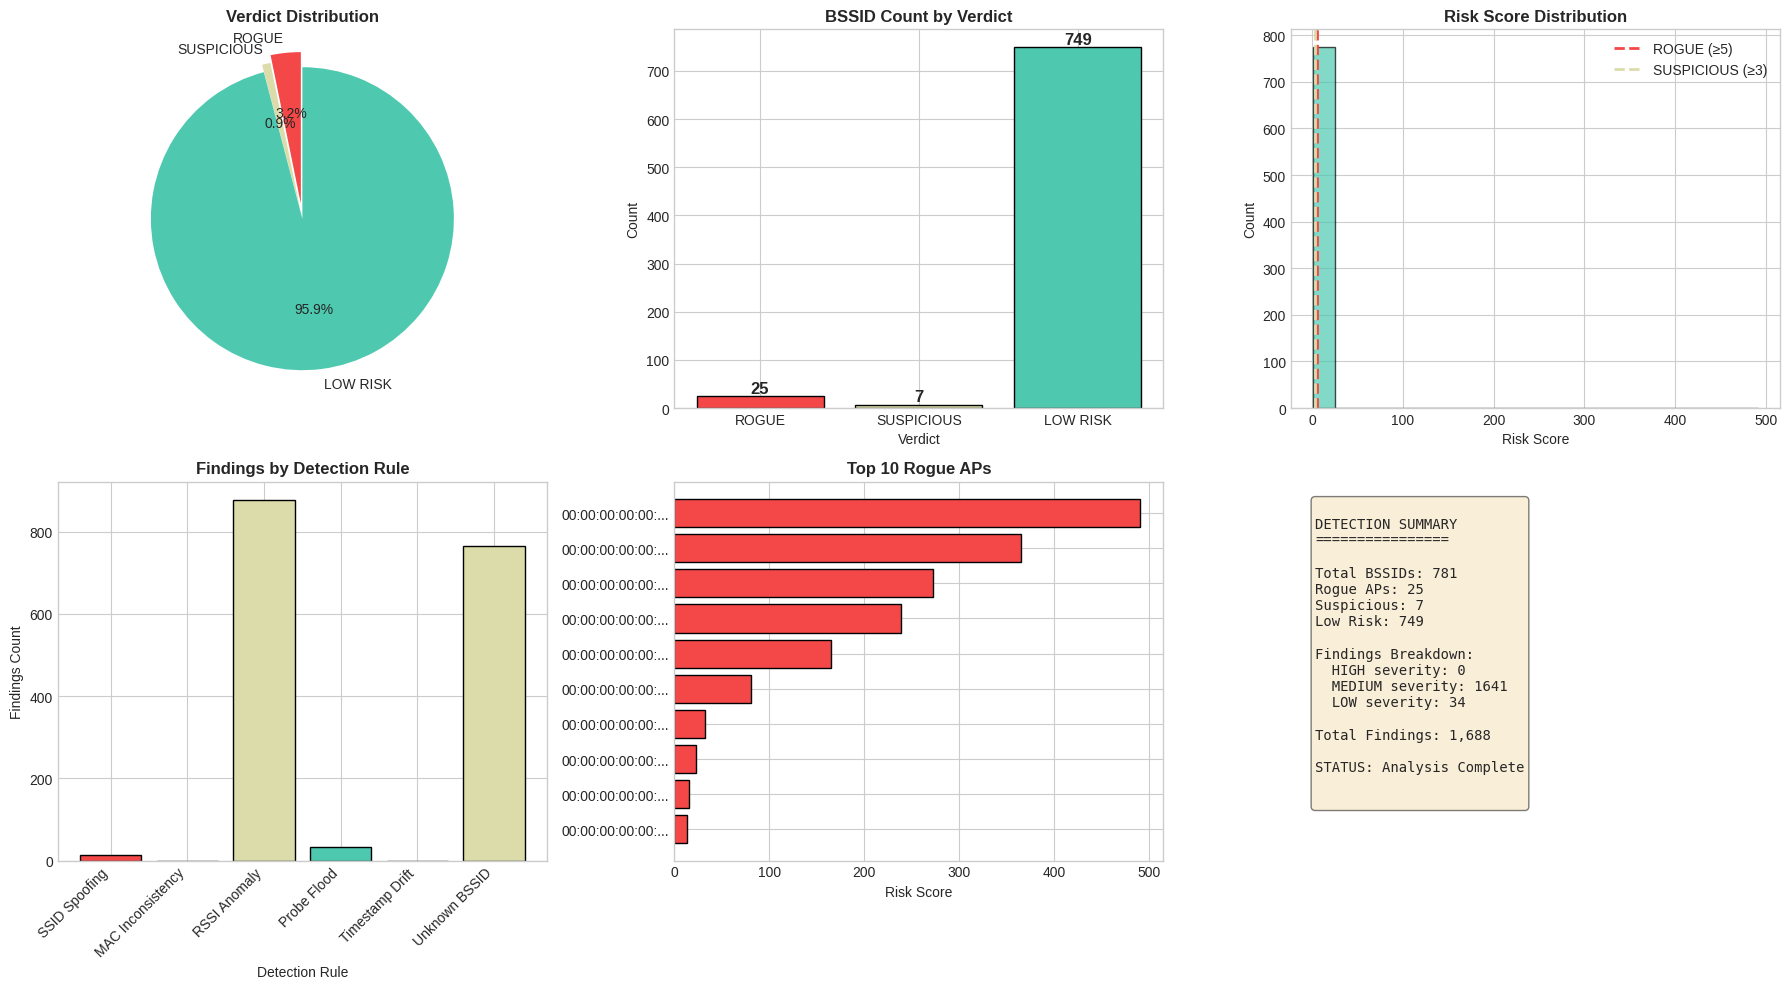

In [22]:
# Verdict Visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Verdict Distribution Pie Chart
ax1 = axes[0, 0]
verdict_data = pd.Series(verdict_counts)
colors = {'ROGUE': COLORS['danger'], 'SUSPICIOUS': COLORS['warning'], 'LOW RISK': COLORS['safe']}
pie_colors = [colors.get(v, COLORS['primary']) for v in verdict_data.index]
ax1.pie(verdict_data.values, labels=verdict_data.index, autopct='%1.1f%%', 
        colors=pie_colors, startangle=90, explode=[0.1, 0.05, 0])
ax1.set_title('Verdict Distribution', fontweight='bold')

# 2. Verdict Bar Chart
ax2 = axes[0, 1]
bars = ax2.bar(verdict_data.index, verdict_data.values, 
               color=[colors.get(v, COLORS['primary']) for v in verdict_data.index],
               edgecolor='black')
ax2.set_xlabel('Verdict')
ax2.set_ylabel('Count')
ax2.set_title('BSSID Count by Verdict', fontweight='bold')
for bar, count in zip(bars, verdict_data.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             str(count), ha='center', va='bottom', fontsize=12, fontweight='bold')

# 3. Score Distribution
ax3 = axes[0, 2]
scores = [r['score'] for r in all_results]
ax3.hist(scores, bins=20, edgecolor='black', alpha=0.7, color=COLORS['primary'])
ax3.axvline(ROGUE_THRESHOLD, color=COLORS['danger'], linestyle='--', linewidth=2, label=f'ROGUE (≥{ROGUE_THRESHOLD})')
ax3.axvline(SUSPICIOUS_THRESHOLD, color=COLORS['warning'], linestyle='--', linewidth=2, label=f'SUSPICIOUS (≥{SUSPICIOUS_THRESHOLD})')
ax3.set_xlabel('Risk Score')
ax3.set_ylabel('Count')
ax3.set_title('Risk Score Distribution', fontweight='bold')
ax3.legend()

# 4. Findings by Rule
ax4 = axes[1, 0]
rule_counts = {
    'SSID Spoofing': len(ssid_findings),
    'MAC Inconsistency': len(mac_findings),
    'RSSI Anomaly': len(rssi_findings),
    'Probe Flood': len(probe_findings),
    'Timestamp Drift': len(drift_findings),
    'Unknown BSSID': len(unknown_findings)
}
severity_colors = {
    'SSID Spoofing': COLORS['danger'],
    'MAC Inconsistency': COLORS['danger'],
    'RSSI Anomaly': COLORS['warning'],
    'Probe Flood': COLORS['safe'],
    'Timestamp Drift': COLORS['safe'],
    'Unknown BSSID': COLORS['warning']
}
bars = ax4.bar(rule_counts.keys(), rule_counts.values(), 
               color=[severity_colors.get(r, COLORS['primary']) for r in rule_counts.keys()],
               edgecolor='black')
ax4.set_xlabel('Detection Rule')
ax4.set_ylabel('Findings Count')
ax4.set_title('Findings by Detection Rule', fontweight='bold')
plt.setp(ax4.xaxis.get_majorticklabels(), rotation=45, ha='right')

# 5. Top 10 Rogue BSSIDs
ax5 = axes[1, 1]
rogue_bssids = [r for r in all_results if r['verdict'] == 'ROGUE'][:10]
if rogue_bssids:
    y_pos = range(len(rogue_bssids))
    ax5.barh(y_pos, [r['score'] for r in rogue_bssids], color=COLORS['danger'], edgecolor='black')
    ax5.set_yticks(y_pos)
    ax5.set_yticklabels([r['bssid'][:15] + '...' if len(r['bssid']) > 15 else r['bssid'] for r in rogue_bssids])
    ax5.set_xlabel('Risk Score')
    ax5.set_title('Top 10 Rogue APs', fontweight='bold')
    ax5.invert_yaxis()
else:
    ax5.text(0.5, 0.5, 'No Rogue APs\nDetected', ha='center', va='center', 
             fontsize=14, transform=ax5.transAxes,
             bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
    ax5.axis('off')

# 6. Finding Counts Summary
ax6 = axes[1, 2]
ax6.axis('off')
summary = f"""
DETECTION SUMMARY
================

Total BSSIDs: {len(all_results)}
Rogue APs: {verdict_counts.get('ROGUE', 0)}
Suspicious: {verdict_counts.get('SUSPICIOUS', 0)}
Low Risk: {verdict_counts.get('LOW RISK', 0)}

Findings Breakdown:
  HIGH severity: {sum(r['finding_counts']['HIGH'] for r in all_results)}
  MEDIUM severity: {sum(r['finding_counts']['MEDIUM'] for r in all_results)}
  LOW severity: {sum(r['finding_counts']['LOW'] for r in all_results)}

Total Findings: {sum(rule_counts.values()):,}

STATUS: Analysis Complete
                    
"""
ax6.text(0.05, 0.95, summary, transform=ax6.transAxes, fontsize=10,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('detection_results_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

---

# 10. Final Comprehensive Dashboard

## Complete Detection System Visualization

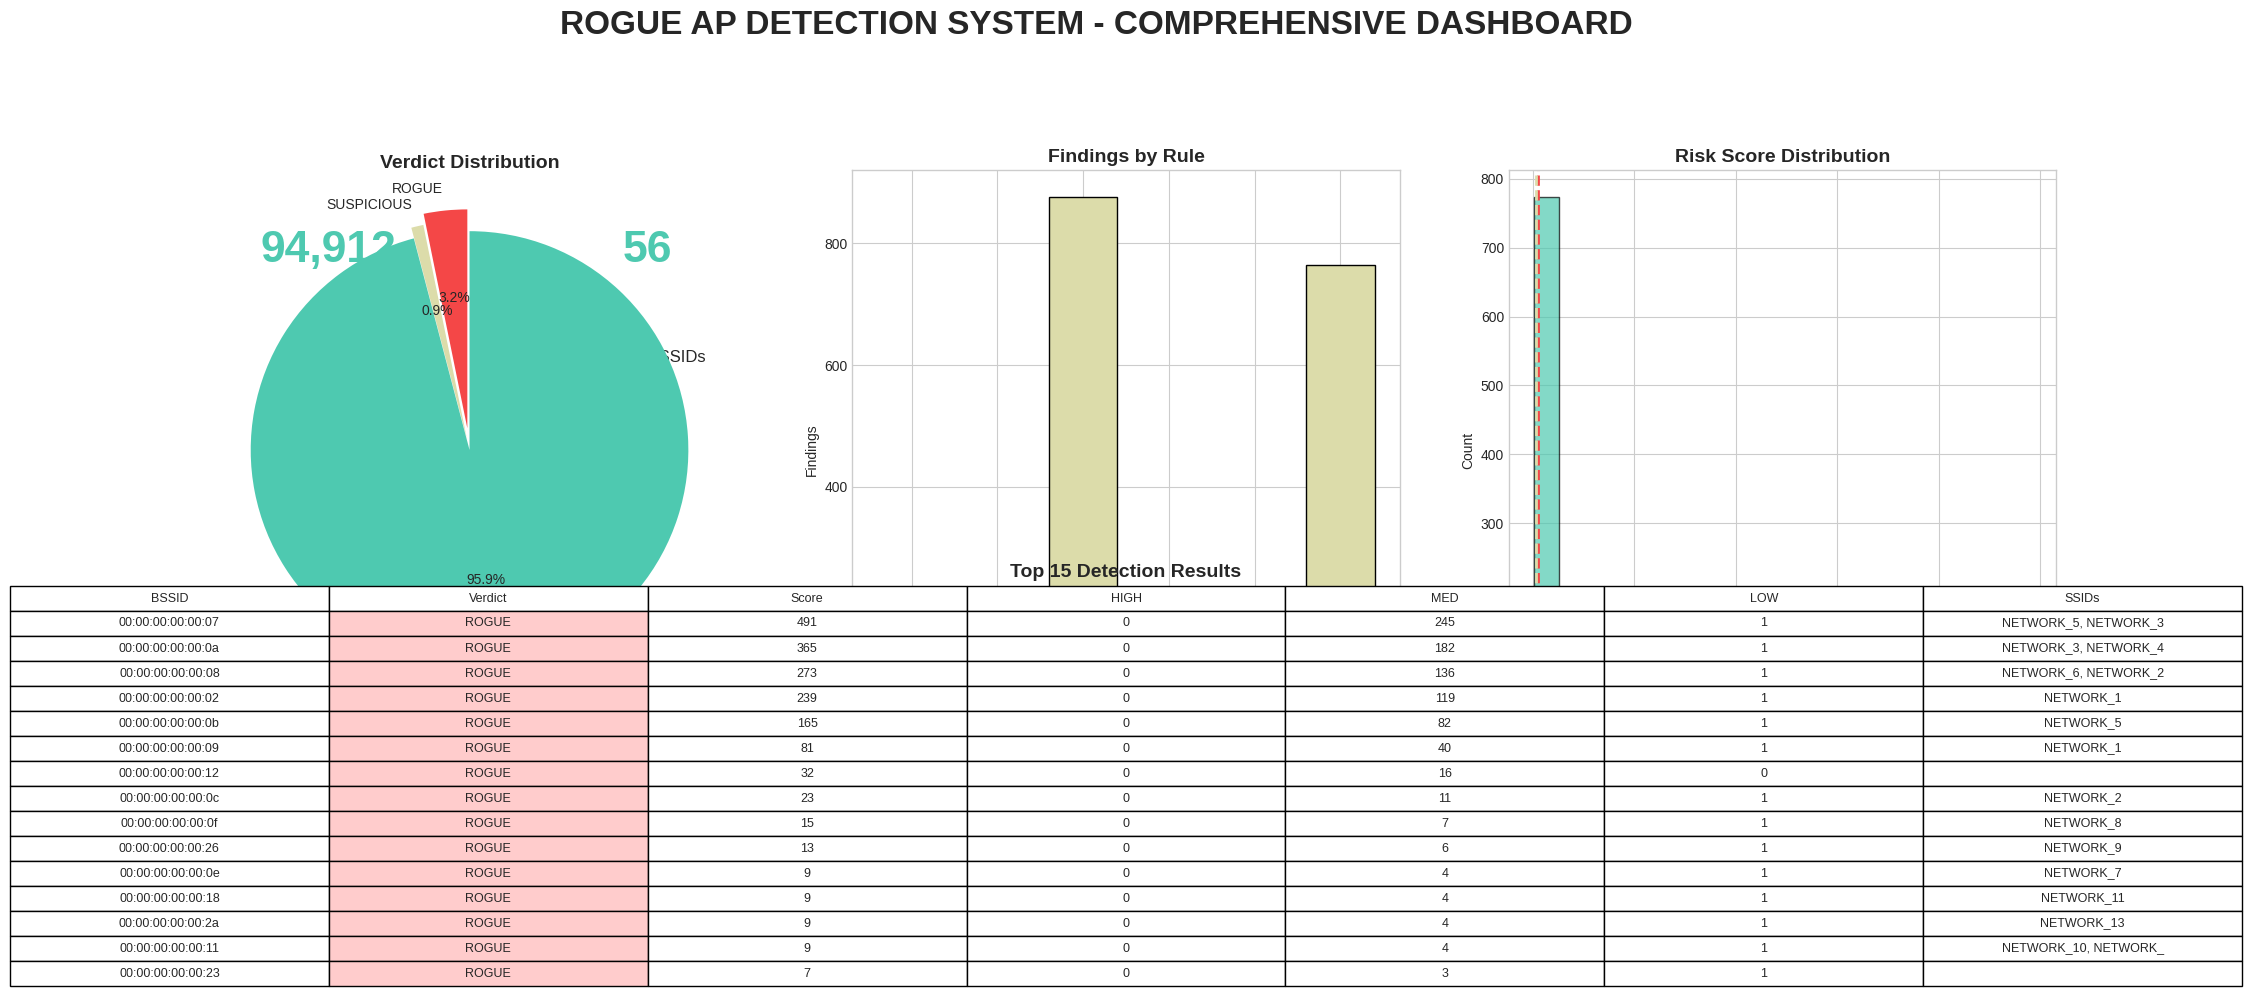

In [23]:
# Final Comprehensive Dashboard
fig = plt.figure(figsize=(24, 16))

# Title
fig.suptitle('ROGUE AP DETECTION SYSTEM - COMPREHENSIVE DASHBOARD', 
             fontsize=24, fontweight='bold', y=0.98)

# Row 1: Overview Stats
ax1 = fig.add_subplot(4, 6, 1)
ax1.text(0.5, 0.7, f'{len(ap_frames):,}', fontsize=32, ha='center', va='center', fontweight='bold', color=COLORS['primary'])
ax1.text(0.5, 0.3, 'Total Frames', fontsize=12, ha='center', va='center')
ax1.axis('off')

ax2 = fig.add_subplot(4, 6, 2)
ax2.text(0.5, 0.7, f'{ap_frames["addr2"].nunique()}', fontsize=32, ha='center', va='center', fontweight='bold', color=COLORS['primary'])
ax2.text(0.5, 0.3, 'Unique BSSIDs', fontsize=12, ha='center', va='center')
ax2.axis('off')

ax3 = fig.add_subplot(4, 6, 3)
ax3.text(0.5, 0.7, str(len(ssid_findings)), fontsize=32, ha='center', va='center', fontweight='bold', color=COLORS['danger'])
ax3.text(0.5, 0.3, 'SSID Spoofing', fontsize=12, ha='center', va='center')
ax3.axis('off')

ax4 = fig.add_subplot(4, 6, 4)
ax4.text(0.5, 0.7, str(len(mac_findings)), fontsize=32, ha='center', va='center', fontweight='bold', color=COLORS['danger'])
ax4.text(0.5, 0.3, 'MAC Issues', fontsize=12, ha='center', va='center')
ax4.axis('off')

ax5 = fig.add_subplot(4, 6, 5)
ax5.text(0.5, 0.7, str(len(rssi_findings)), fontsize=32, ha='center', va='center', fontweight='bold', color=COLORS['warning'])
ax5.text(0.5, 0.3, 'RSSI Anomalies', fontsize=12, ha='center', va='center')
ax5.axis('off')

ax6 = fig.add_subplot(4, 6, 6)
ax6.text(0.5, 0.7, str(len(probe_findings)), fontsize=32, ha='center', va='center', fontweight='bold', color=COLORS['safe'])
ax6.text(0.5, 0.3, 'Probe Floods', fontsize=12, ha='center', va='center')
ax6.axis('off')

# Row 2: Main Visualizations
ax7 = fig.add_subplot(2, 3, 1)
verdict_data = pd.Series(verdict_counts)
colors = {'ROGUE': COLORS['danger'], 'SUSPICIOUS': COLORS['warning'], 'LOW RISK': COLORS['safe']}
pie_colors = [colors.get(v, COLORS['primary']) for v in verdict_data.index]
ax7.pie(verdict_data.values, labels=verdict_data.index, autopct='%1.1f%%', 
        colors=pie_colors, startangle=90, explode=[0.1, 0.05, 0])
ax7.set_title('Verdict Distribution', fontsize=14, fontweight='bold')

ax8 = fig.add_subplot(2, 3, 2)
rule_counts = {
    'SSID Spoof': len(ssid_findings),
    'MAC Issue': len(mac_findings),
    'RSSI Anom': len(rssi_findings),
    'Probe Flood': len(probe_findings),
    'Time Drift': len(drift_findings),
    'Unknown': len(unknown_findings)
}
ax8.bar(rule_counts.keys(), rule_counts.values(), color=[COLORS['danger'], COLORS['danger'], COLORS['warning'], COLORS['safe'], COLORS['safe'], COLORS['warning']], edgecolor='black')
ax8.set_ylabel('Findings')
ax8.set_title('Findings by Rule', fontsize=14, fontweight='bold')
plt.setp(ax8.xaxis.get_majorticklabels(), rotation=45, ha='right')

ax9 = fig.add_subplot(2, 3, 3)
scores = [r['score'] for r in all_results]
ax9.hist(scores, bins=20, edgecolor='black', alpha=0.7, color=COLORS['primary'])
ax9.axvline(ROGUE_THRESHOLD, color=COLORS['danger'], linestyle='--', linewidth=2)
ax9.axvline(SUSPICIOUS_THRESHOLD, color=COLORS['warning'], linestyle='--', linewidth=2)
ax9.set_xlabel('Risk Score')
ax9.set_ylabel('Count')
ax9.set_title('Risk Score Distribution', fontsize=14, fontweight='bold')

# Row 3: Top Findings Table
ax10 = fig.add_subplot(3, 1, 2)
ax10.axis('off')

table_data = []
for r in all_results[:15]:
    table_data.append([
        r['bssid'][:20],
        r['verdict'],
        str(r['score']),
        str(r['finding_counts']['HIGH']),
        str(r['finding_counts']['MEDIUM']),
        str(r['finding_counts']['LOW']),
        ', '.join(r['ssids'][:2])[:20]
    ])

col_labels = ['BSSID', 'Verdict', 'Score', 'HIGH', 'MED', 'LOW', 'SSIDs']
table = ax10.table(cellText=table_data, colLabels=col_labels, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)

# Color code verdict cells
for i, r in enumerate(all_results[:15]):
    verdict = r['verdict']
    if verdict == 'ROGUE':
        table[(i+1, 1)].set_facecolor('#FFCCCC')
    elif verdict == 'SUSPICIOUS':
        table[(i+1, 1)].set_facecolor('#FFF2CC')
    else:
        table[(i+1, 1)].set_facecolor('#E2EFDA')

ax10.set_title('Top 15 Detection Results', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('comprehensive_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
# Final Summary
print("=" * 70)
print("ROGUE AP DETECTION SYSTEM - FINAL SUMMARY")
print("=" * 70)

print(f"\n{'='*40}")
print("DATASET STATISTICS")
print(f"{'='*40}")
print(f"  Total frames: {len(df):,}")
print(f"  AP frames: {len(ap_frames):,}")
print(f"  Unique BSSIDs: {ap_frames['addr2'].nunique()}")
print(f"  Unique SSIDs: {ap_frames[ap_frames['SSID'] != '']['SSID'].nunique()}")

print(f"\n{'='*40}")
print("DETECTION RESULTS")
print(f"{'='*40}")
print(f"  SSID Spoofing: {len(ssid_findings)} findings")
print(f"  MAC Inconsistency: {len(mac_findings)} findings")
print(f"  RSSI Anomaly: {len(rssi_findings)} findings")
print(f"  Probe Response Flood: {len(probe_findings)} findings")
print(f"  MAC Timestamp Drift: {len(drift_findings)} findings")
print(f"  Unknown BSSID: {len(unknown_findings)} findings")

print(f"\n{'='*40}")
print("VERDICT SUMMARY")
print(f"{'='*40}")
for verdict, count in sorted(verdict_counts.items()):
    pct = 100 * count / len(all_results)
    print(f"  {verdict}: {count} BSSIDs ({pct:.1f}%)")

print(f"\n{'='*40}")
print("TOTAL FINDINGS")
print(f"{'='*40}")
print(f"  {len(ssid_findings) + len(mac_findings) + len(rssi_findings) + len(probe_findings) + len(drift_findings) + len(unknown_findings):,}")

print("\n" + "=" * 70)

ROGUE AP DETECTION SYSTEM - FINAL SUMMARY

DATASET STATISTICS
  Total frames: 97,290
  AP frames: 94,912
  Unique BSSIDs: 56
  Unique SSIDs: 20

DETECTION RESULTS
  SSID Spoofing: 13 findings
  MAC Inconsistency: 0 findings
  RSSI Anomaly: 877 findings
  Probe Response Flood: 34 findings
  MAC Timestamp Drift: 0 findings
  Unknown BSSID: 764 findings

VERDICT SUMMARY
  LOW RISK: 749 BSSIDs (95.9%)
  ROGUE: 25 BSSIDs (3.2%)
  SUSPICIOUS: 7 BSSIDs (0.9%)

TOTAL FINDINGS
  1,688



---

# Conclusions

This notebook demonstrates the implementation of six detection rules for identifying rogue access points in IEEE 802.11 wireless networks:

1. **SSID Spoofing** - Detects evil twin attacks where the same SSID is broadcast by multiple BSSIDs
2. **MAC Address Inconsistency** - Identifies frame injection attacks based on IEEE 802.11 protocol violations
3. **RSSI Anomaly** - Uses statistical analysis (Z-score) and machine learning (Isolation Forest) to detect signal anomalies
4. **Probe Response Flood** - Identifies honeypot APs sending excessive probe responses
5. **MAC Timestamp Drift** - Detects replay attacks and software-defined APs with poor clock synchronization
6. **Unknown BSSID** - Flags access points not in the authorized whitelist

## Visualizations Generated

| File | Description |
|------|-------------|
| `data_overview_dashboard.png` | Comprehensive data overview |
| `time_series_analysis.png` | Temporal analysis |
| `network_activity.png` | Network activity patterns |
| `ssid_spoofing_analysis.png` | SSID spoofing findings |
| `mac_consistency_analysis.png` | MAC address analysis |
| `rssi_anomaly_analysis.png` | RSSI anomaly detection |
| `isolation_forest_analysis.png` | ML-based anomaly detection |
| `probe_flood_analysis.png` | Probe response flood |
| `timestamp_drift_analysis.png` | Timestamp drift analysis |
| `unknown_bssid_analysis.png` | Unknown BSSID detection |
| `detection_results_dashboard.png` | Detection results summary |
| `comprehensive_dashboard.png` | Complete system dashboard |